<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_ZeroDayDetection_Nhlapo2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parameterised QSVM with data-driven entanglement for zero-day exploit detection: Nhlapo et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Steven Jabulani Nhlapo, Elodie Ngoie Mutombo and Mike Nkongolo Wa Nkongolo, "Parameterised Quantum SVM with
> Data-Driven Entanglement for Zero-Day Exploit Detection", *Computers* 14(8), 331, 2025.
> DOI: [10.3390/computers14080331](https://doi.org/10.3390/computers14080331)

**What the notebook does.** It downloads the public **UGRansome** network-flow dataset (the same data the paper uses), cleans it
the way Section 3.1 of the paper describes, ranks the features with the chi-squared test, and classifies every flow as
**A** (anomaly, possible zero-day), **S** (signature, known attack) or **SS** (synthetic signature). It then trains

* the paper's classical models (linear SVM, SVM with borderline-SMOTE and with SMOTEENN, Naive Bayes, Random Forest, XGBoost, a
  voting ensemble), and
* the paper's **quantum SVM**: a quantum kernel built from a *parameterised, nonlinear angle encoding*
  `RZ(gamma_j sin(omega_j x_j + phi_j))` and `RY(pi x_j)` with **CZ gates only between features whose mutual information exceeds
  a threshold tau = 0.05** (the "sparse, data-driven entanglement"), simulated exactly with statevectors, with 3, 4 and 6 qubits;
  it is compared with the standard `ZZFeatureMap` kernel and with ablations (untrained encoding, no entanglement, full
  entanglement, no feature selection).

**How to run.** Colab: Runtime -> Run all (CPU runtime is enough). `FAST_MODE = True` (the setting stored in this notebook, with its outputs) is designed for about 10 minutes on an idle laptop (27 minutes on the loaded shared CPU where it was executed); set it to `False` for the larger samples (3,000 / 5,000 quantum flows, 89.5k classical flows), three seeds and the 6-qubit model, which takes well over an hour on a CPU. No GPU, no IBM account
and no Hugging Face token are needed: the data come from a public figshare record.

**What you get at the end:** the paper's tables re-computed (Tables 8-12 and the confusion matrices of Fig. 6), the
circuit that is actually executed for 3, 4 and 6 qubits, dataset plots, and a side-by-side table that states for every claim of the
paper whether this notebook *reproduced* it, *did not reach* it, or *cannot check* it.

## The paper in one page

**Problem.** Signature-based intrusion detection cannot see zero-day exploits. The authors classify network flows of the
UGRansome dataset into three target classes: *anomaly* (A, may contain zero-day behaviour), *signature* (S, known attacks such as
DoS and spam) and *synthetic signature* (SS, simulated attacks).

**Data.** UGRansome (Kaggle `nkongolo/ugransome-dataset`, University of Pretoria repository, DOI 10.25403/UPresearchdata.25215530):
149,043 labelled flows, 14 columns (time, protocol, TCP flag, ransomware family, cluster, seed and exploit Bitcoin address, BTC, USD,
netflow bytes, IP class, threat type, port, and the target `Prediction`). After cleaning the paper has 111,904 flows,
split 80 : 20 into 89,523 training and 22,381 test flows.

**Pre-processing.** Fix spelling (`Protcol`, `SeddAddress`, botnet labels), drop one malformed `expAddress`, filter outliers in
`time`, `USD`, `BTC`, `clusters`, `netflow_bytes`, add 11 to the negative `time` values; label-encode text columns; min-max scale to
[0, 1]; keep the **top k = 6 features by the chi-squared score**.

**Classical models.** `LinearSVC` (64 % accuracy), SVM with borderline-SMOTE (99.8 %) and SMOTEENN (98.1 %), Naive Bayes (99 %),
Random Forest, voting ensemble and XGBoost (all 100 %).

**Quantum model (Section 3.5-3.7, 4.2).** Each scaled feature `x_j` in [0, 1] is encoded by
`RY(pi x_j) RZ(gamma_j sin(omega_j x_j + phi_j))` (trainable `gamma, omega, phi`, Adam, learning rate 0.001), followed by `CZ` gates on
the edges `(i, j)` with mutual information `I(x_i; x_j) > tau = 0.05`. The kernel is the state fidelity
`K(x, x') = |<psi(x)|psi(x')>|^2`, used in an SVM with precomputed kernel. 3- and 4-qubit versions, `aer_simulator_statevector`,
`ZZFeatureMap`-style circuit with 2 repetitions in Section 4.2.

**Claims we can test.** Table 8: linear SVM 0.64 accuracy. Tables 9-10: SMOTE variants 0.998 / 0.981. Table 11: NB 0.99, RFC /
ensemble / XGBoost 1.00. Table 12 and 16: QSVM accuracy 0.9794 (3 qubits) and 0.9911 (4 qubits), F1 0.9796 / 0.9825, versus 0.57-0.63
for classical SVMs with linear, polynomial and RBF kernels on the same inputs; abstract: 99.89 % accuracy and 98.95 % F1. Table 16:
removing the feature-selection step lowers the F1 score (4 qubits: 0.9825 to 0.9328).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | UGRansome, 111,904 flows after cleaning | Same public CSV from figshare (149,043 rows); our cleaning leaves a similar number (printed in Section 1) |
| Outlier filter | "outliers were filtered", rule not given | `\|z\| < 2` on `Time, Clusters, BTC, USD, Netflow_Bytes` (CHOICE; this rule keeps almost exactly the paper's 111.9k rows) |
| Split | random 80 : 20 | stratified 80 : 20, `random_state=42` (CHOICE: stratified) |
| Feature selection | chi-squared, k = 6 (qubits: 3 and 4) | chi-squared fitted **on the training split only**; the top 3, 4 and 6 features give 3, 4 and 6 qubits |
| Encoding | `RY(pi x) RZ(f(x))` on `\|0>` | **a Hadamard layer is added first** (CHOICE). Applied to `\|0>` an `RZ` is only a global phase, so the trainable `gamma, omega, phi` would have no effect at all; Section 4 verifies this numerically |
| Circuit depth | "1 to 3 layers"; Section 4.2 says 2 repetitions | `REPS = 2` repetitions of `H, RZ(f), RY, CZ-edges` (CHOICE) |
| Trainable parameters | Adam, learning rate 0.001, loss not given | Adam on the **centred kernel-target alignment** of the training data, learning rate 0.05 (CHOICE; 0.001 hardly moves in a few dozen steps), numerical gradients |
| Mutual information | "I(x_i; x_j) > tau, tau = 0.05" | histogram estimate with 10 equal-width bins, in nats, on the training split (CHOICE) |
| Kernel | fidelity of statevectors | exact statevector fidelity; a NumPy simulator is verified against Qiskit `FidelityStatevectorKernel` + `QSVC` with `np.allclose` |
| Bandwidth / `C` | `C` "default or tuned" | angle scale and `C` chosen on a validation split of the training data only |
| Sample size of the quantum SVM | not stated (3 / 4 qubits "on the dataset") | `N_TRAIN_Q` training and `N_TEST_Q` test flows drawn from the 80 : 20 split (CHOICE; set in the configuration cell) |
| Shots | 1024 shots on a statevector backend (contradictory) | exact statevector, no shot noise |
| SMOTE | resampled data evaluated on 29,794 "test" rows | resampling is fitted on the **training split only**; the paper's variant (resample first, split afterwards) is also run to show the leakage |
| "t-SNE feature selection" ablation (Tables 16-17) | t-SNE is said to select features | t-SNE cannot select features; we run the ablation that makes sense: chi-squared selection versus the first columns |
| Hardware | none (noiseless simulation) | none; `IBM_TOKEN` is kept in the configuration for symmetry but no cell uses hardware |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc "imbalanced-learn==0.14.2" "xgboost==3.4.1"
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit and Qiskit Machine Learning already present; skipping pip install.")

Qiskit and Qiskit Machine Learning already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant is here ----------------
FAST_MODE = True          # True: a few minutes (small samples, 1 seed, 3 and 4 qubits).  False: the full run (see the numbers below).
SEED      = 42            # CHOICE: the paper does not state a seed
IBM_TOKEN = ""            # not used: the paper is a noiseless simulation; no hardware cell exists

# --- data and cleaning (paper, Section 3.1, 3.9) ---
DATA_DIR    = "data"      # cache folder for the downloaded CSV
DATA_PATH   = None        # or the path of an uploaded UGRansome_Dataset.csv (then no download is attempted)
TEST_SIZE   = 0.20        # paper: 80 : 20
OUTLIER_Z   = 2.0         # CHOICE: |z| < 2 on the five numeric columns (the paper does not give its rule)
TIME_OFFSET = 11          # paper: +11 s on all `time` values because of negatives

# --- quantum model (paper, Sections 3.5-3.7, 4.2) ---
REPS        = 2           # repetitions of (H, RZ(f), RY, CZ edges); paper Section 4.2: two repetitions
TAU         = 0.05        # mutual-information threshold for a CZ edge (paper Table 6)
MI_BINS     = 10          # CHOICE: histogram bins for the mutual-information estimate
KTA_LR      = 0.05        # CHOICE: Adam learning rate for gamma/omega/phi (the paper lists 0.001)
VAL_FRACTION = 0.25       # inner validation split of the quantum training sample (scale and C are chosen here)
N_CHECK_TRAIN, N_CHECK_TEST = 40, 25   # sizes of the Qiskit cross-check (FidelityStatevectorKernel / QSVC)

if FAST_MODE:
    SEEDS            = [42]               # seeds for the quantum sample draw and the encoding initialisation
    QUBIT_COUNTS     = [3, 4]             # paper: 3 and 4 qubits
    N_TRAIN_Q, N_TEST_Q = 240, 600        # CHOICE: flows used by the quantum kernel (train / test)
    N_KTA, KTA_STEPS = 120, 15            # alignment training: flows and Adam steps
    SCALE_GRID       = [1.0]              # CHOICE: angle scale candidates (multiplies the RY angle pi*x)
    C_GRID           = [1.0, 10.0]        # CHOICE: SVM C candidates
    N_CLASSICAL_TRAIN = 15000             # classical models of Section 3 use this many training rows (None = all 89.5k)
else:
    SEEDS            = [42, 43, 44]
    QUBIT_COUNTS     = [3, 4, 6]          # 6 = the paper's k = 6 features, one qubit each
    N_TRAIN_Q, N_TEST_Q = 3000, 5000
    N_KTA, KTA_STEPS = 300, 60
    SCALE_GRID       = [0.5, 1.0, 2.0]
    C_GRID           = [0.1, 1.0, 10.0, 100.0]
    N_CLASSICAL_TRAIN = None
ABLATION_QUBITS = 4                       # the "no feature selection" ablation is run for this qubit count

In [3]:
import os, time, warnings, hashlib, itertools, textwrap
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import requests
from IPython.display import display
import sklearn, xgboost, imblearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler, StandardScaler
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix, f1_score,
                             roc_auc_score, mutual_info_score)
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import SGDClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.combine import SMOTEENN
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| imbalanced-learn", imblearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| qubit counts", QUBIT_COUNTS, "| quantum sample", N_TRAIN_Q, "/", N_TEST_Q)

qiskit 2.5.2 | scikit-learn 1.9.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2 | numpy 2.5.4 | pandas 3.0.6
FAST_MODE = True | seeds [42] | qubit counts [3, 4] | quantum sample 240 / 600


## 1. The UGRansome dataset: download and cleaning (paper, Section 3.1)

UGRansome (Nkongolo, University of Pretoria) combines real network flows with ransomware and zero-day exploit records. The
paper's data statement points to the figshare record `10.25403/UPresearchdata.25215530` (file `UGRansome_Dataset.csv`,
10 MB, no login). The notebook downloads exactly that file and checks its MD5 sum. The paper's own cleaning steps are reproduced:

1. correct the misspelt column names (`Protcol`, `SeddAddress`) and the misspelt botnet labels in `Threats`;
2. remove the one malformed `ExpAddress` value (`"1"`, not the expected 8 characters);
3. add 11 to `Time` (it contains negative values);
4. filter outliers in `Time, Clusters, BTC, USD, Netflow_Bytes` (the paper does not give the rule: CHOICE `|z| < 2`);
5. the paper reports no duplicates and no missing values, which we verify.

In [4]:
FIGSHARE_URLS = ["https://ndownloader.figshare.com/files/44537567", "https://figshare.com/ndownloader/files/44537567"]
EXPECTED_MD5  = "55d60eda81c0195d4bae394309fe7d84"     # md5 published by figshare for UGRansome_Dataset.csv

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def get_ugransome():
    if DATA_PATH:                                    # option 1: the reader uploaded the file
        return DATA_PATH
    path = os.path.join(DATA_DIR, "UGRansome_Dataset.csv")
    if os.path.exists(path) and md5(path) == EXPECTED_MD5:
        return path
    for url in FIGSHARE_URLS:                        # option 2: public figshare record (no token needed)
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            open(path, "wb").write(r.content)
            if md5(path) == EXPECTED_MD5:
                return path
            print("md5 mismatch for", url)
        except Exception as e:
            print("download failed:", url, str(e)[:80])
    raise RuntimeError("Could not download UGRansome. Download UGRansome_Dataset.csv from "
                       "https://doi.org/10.25403/UPresearchdata.25215530.v1 and set DATA_PATH.")

csv_path = get_ugransome()
raw = pd.read_csv(csv_path)
print("file:", csv_path, "| md5 ok:", md5(csv_path) == EXPECTED_MD5, "| raw shape:", raw.shape)
print("duplicated rows:", int(raw.duplicated().sum()), "| missing values:", int(raw.isna().sum().sum()))

df = raw.rename(columns={"Protcol": "Protocol", "SeddAddress": "SeedAddress"})
df.columns = [c.strip() for c in df.columns]
df["Threats"] = df["Threats"].replace({"Bonet": "Botnet", "NerisBonet": "NerisBotnet"})   # mislabelled botnet entries
n0 = len(df)
df = df[df["ExpAddress"].str.len() == 8].copy()                                          # malformed ExpAddress "1"
print("rows removed (malformed ExpAddress):", n0 - len(df))
if df["Time"].min() < 0:
    df["Time"] = df["Time"] + TIME_OFFSET
OUTLIER_COLS = ["Time", "Clusters", "BTC", "USD", "Netflow_Bytes"]
z = (df[OUTLIER_COLS] - df[OUTLIER_COLS].mean()) / df[OUTLIER_COLS].std()
n1 = len(df)
df = df[(z.abs() < OUTLIER_Z).all(axis=1)].reset_index(drop=True)
print(f"rows removed by the |z| < {OUTLIER_Z} outlier filter: {n1 - len(df)}")
print(f"cleaned dataset: {len(df):,} flows   (paper: 111,904 = 89,523 train + 22,381 test)")

file: data\UGRansome_Dataset.csv | md5 ok: True | raw shape: (149043, 14)


duplicated rows: 0 | missing values: 0


rows removed (malformed ExpAddress): 73


rows removed by the |z| < 2.0 outlier filter: 37025
cleaned dataset: 111,945 flows   (paper: 111,904 = 89,523 train + 22,381 test)


## 2. Split and pre-processing, fitted on the training split only

The paper applies a random 80 : 20 split (Section 3.9). Everything that learns from data is fitted **on the 80 % training part only**:

* text columns -> integer codes (`OrdinalEncoder`; a category not seen in training would get `-1`),
* min-max scaling to [0, 1] (test values clipped to [0, 1]),
* chi-squared feature ranking (`SelectKBest(chi2)`); the top 3, 4 and 6 features feed the 3-, 4- and 6-qubit circuits
  (one feature per qubit).

In [5]:
CLASSES = ["A", "S", "SS"]
CAT = ["Protocol", "Flag", "Family", "SeedAddress", "ExpAddress", "IPaddress", "Threats"]
FEATURES = [c for c in df.columns if c != "Prediction"]                  # natural column order (13 features)

train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df["Prediction"], random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(f"train {len(train_df):,} (paper 89,523) | test {len(test_df):,} (paper 22,381)")

enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(train_df[CAT])
def encode(d):
    X = d[FEATURES].copy()
    X[CAT] = enc.transform(d[CAT])
    return X.astype(float)
scaler = MinMaxScaler().fit(encode(train_df))
Xtr = np.clip(scaler.transform(encode(train_df)), 0, 1)
Xte = np.clip(scaler.transform(encode(test_df)), 0, 1)
ytr = train_df["Prediction"].map({c: i for i, c in enumerate(CLASSES)}).values
yte = test_df["Prediction"].map({c: i for i, c in enumerate(CLASSES)}).values

sel = SelectKBest(chi2, k="all").fit(Xtr, ytr)
chi_scores = pd.Series(sel.scores_, index=FEATURES).sort_values(ascending=False)
RANK = list(chi_scores.index)
feat_idx = {n: [FEATURES.index(f) for f in RANK[:n]] for n in (3, 4, 6, 13)}
print("chi-squared ranking (training split):")
display(chi_scores.round(1).to_frame("chi2 score").T)
print("top-3:", RANK[:3], "| top-4:", RANK[:4], "| top-6:", RANK[:6])
print("paper: top-6 are time-independent attributes such as expAddress, seedAddress, port, clusters, USD (Figs. 3-4).")

train 89,556 (paper 89,523) | test 22,389 (paper 22,381)


chi-squared ranking (training split):


,USD,ExpAddress,Port,Clusters,Netflow_Bytes,Threats,SeedAddress,Flag,Protocol,BTC,IPaddress,Time,Family
chi2 score,9650.3,8003.1,5980.0,2836.2,1672.2,1127.9,1104.3,866.9,688.9,277.9,208.7,152.0,92.4


top-3: ['USD', 'ExpAddress', 'Port'] | top-4: ['USD', 'ExpAddress', 'Port', 'Clusters'] | top-6: ['USD', 'ExpAddress', 'Port', 'Clusters', 'Netflow_Bytes', 'Threats']
paper: top-6 are time-independent attributes such as expAddress, seedAddress, port, clusters, USD (Figs. 3-4).


## Dataset Exploration and Visualisation

Everything below uses the real UGRansome flows. Colours are the ground-truth labels: first the paper's target `Prediction`
(A / S / SS), then the attack type recorded in `Threats` (nine values, kept as a multiclass label). Points are plotted from the
training split; projections are fitted on the training split only.

In [6]:
print("shape of the raw file :", raw.shape, "| cleaned:", df.shape)
print("feature names         :", FEATURES)
print("target `Prediction`   :", dict(df["Prediction"].value_counts()))
print("attack type `Threats` :", dict(df["Threats"].value_counts()))
print("ransomware `Family`   :", dict(df["Family"].value_counts()))
print("\nclass counts in the splits:")
display(pd.DataFrame({"train": train_df["Prediction"].value_counts(), "test": test_df["Prediction"].value_counts()}).loc[CLASSES])
display(df.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])

shape of the raw file :

 (149043, 14) | cleaned: (111945, 14)
feature names         : ['Time', 'Protocol', 'Flag', 'Family', 'Clusters', 'SeedAddress', 'ExpAddress', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats', 'Port']
target `Prediction`   : {'S': np.int64(51669), 'SS': np.int64(33970), 'A': np.int64(26306)}
attack type `Threats` : {'SSH': np.int64(19322), 'Spam': np.int64(16900), 'Blacklist': np.int64(15279), 'UDP Scan': np.int64(14720), 'Botnet': np.int64(13045), 'DoS': np.int64(11421), 'Port Scanning': np.int64(9779), 'Scan': np.int64(8593), 'NerisBotnet': np.int64(2886)}


ransomware `Family`   : {'Locky': np.int64(18691), 'SamSam': np.int64(15719), 'WannaCry': np.int64(13174), 'JigSaw': np.int64(9573), 'Flyper': np.int64(8795), 'DMALocker': np.int64(8008), 'CryptXXX': np.int64(7752), 'APT': np.int64(7509), 'Globe': np.int64(5821), 'Razy': np.int64(5221), 'EDA2': np.int64(4533), 'TowerWeb': np.int64(2886), 'Cryptohitman': np.int64(2686), 'NoobCrypt': np.int64(876), 'CryptoLocker': np.int64(495), 'CryptoLocker2015': np.int64(144), 'Globev3': np.int64(62)}

class counts in the splits:


,train,test
Prediction,,
A,21045,5261
S,41335,10334
SS,27176,6794


,count,unique,top,mean,min,max
Time,111945.0,NaN,NaN,30.67434,3.0,64.0
Protocol,111945,3,TCP,NaN,NaN,NaN
Flag,111945,9,AF,NaN,NaN,NaN
Family,111945,17,Locky,NaN,NaN,NaN
Clusters,111945.0,NaN,NaN,1.23248,1.0,8.0
SeedAddress,111945,5,1DA11mPS,NaN,NaN,NaN
ExpAddress,111945,6,1DiCeTjB,NaN,NaN,NaN
BTC,111945.0,NaN,NaN,18.835955,1.0,232.0
USD,111945.0,NaN,NaN,10214.331931,1.0,50991.0
Netflow_Bytes,111945.0,NaN,NaN,1874.112439,3.0,6564.0


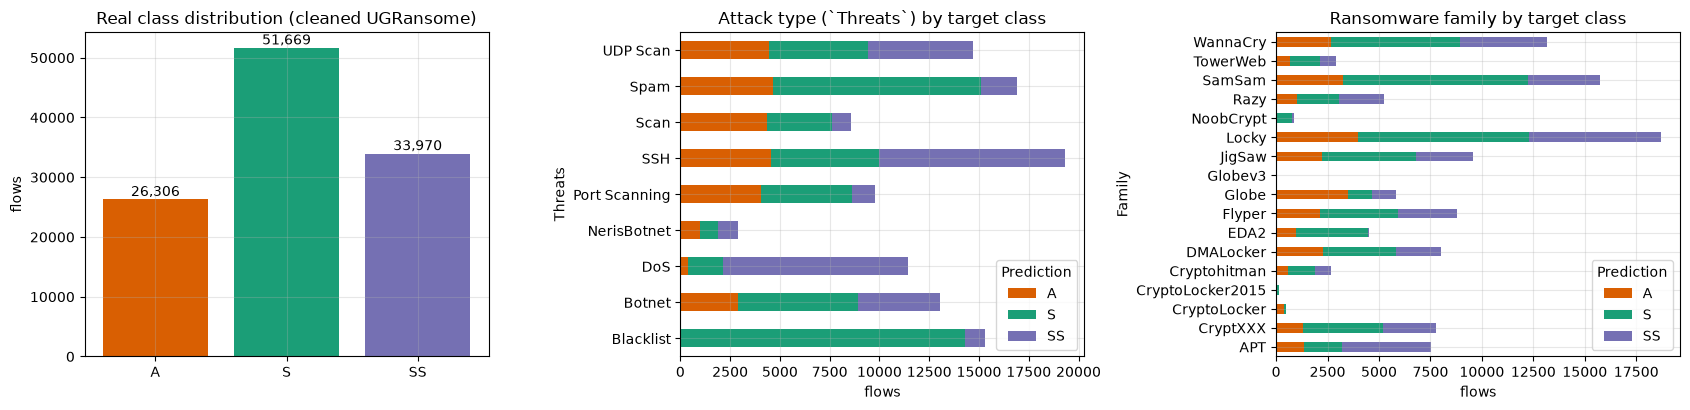

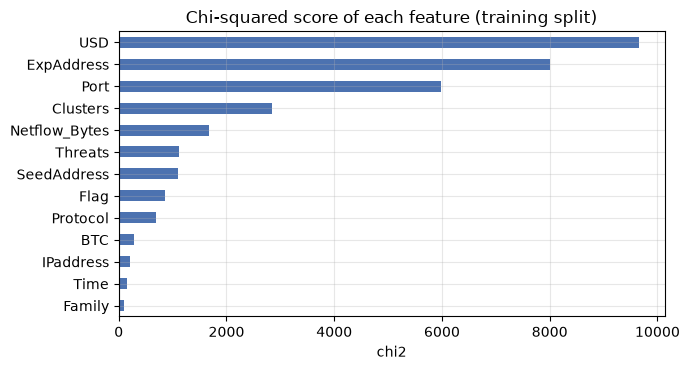

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cnt = df["Prediction"].value_counts().loc[CLASSES]
ax[0].bar(CLASSES, cnt.values, color=["#d95f02", "#1b9e77", "#7570b3"])
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[0].set_title("Real class distribution (cleaned UGRansome)"); ax[0].set_ylabel("flows")
ct = pd.crosstab(df["Threats"], df["Prediction"])[CLASSES]
ct.plot(kind="barh", stacked=True, ax=ax[1], color=["#d95f02", "#1b9e77", "#7570b3"])
ax[1].set_title("Attack type (`Threats`) by target class"); ax[1].set_xlabel("flows")
cf = pd.crosstab(df["Family"], df["Prediction"])[CLASSES]
cf.plot(kind="barh", stacked=True, ax=ax[2], color=["#d95f02", "#1b9e77", "#7570b3"])
ax[2].set_title("Ransomware family by target class"); ax[2].set_xlabel("flows")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
chi_scores.iloc[::-1].plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_title("Chi-squared score of each feature (training split)"); ax.set_xlabel("chi2")
plt.tight_layout(); plt.show()

PCA on the 6 selected features, explained variance: [0.342 0.282]


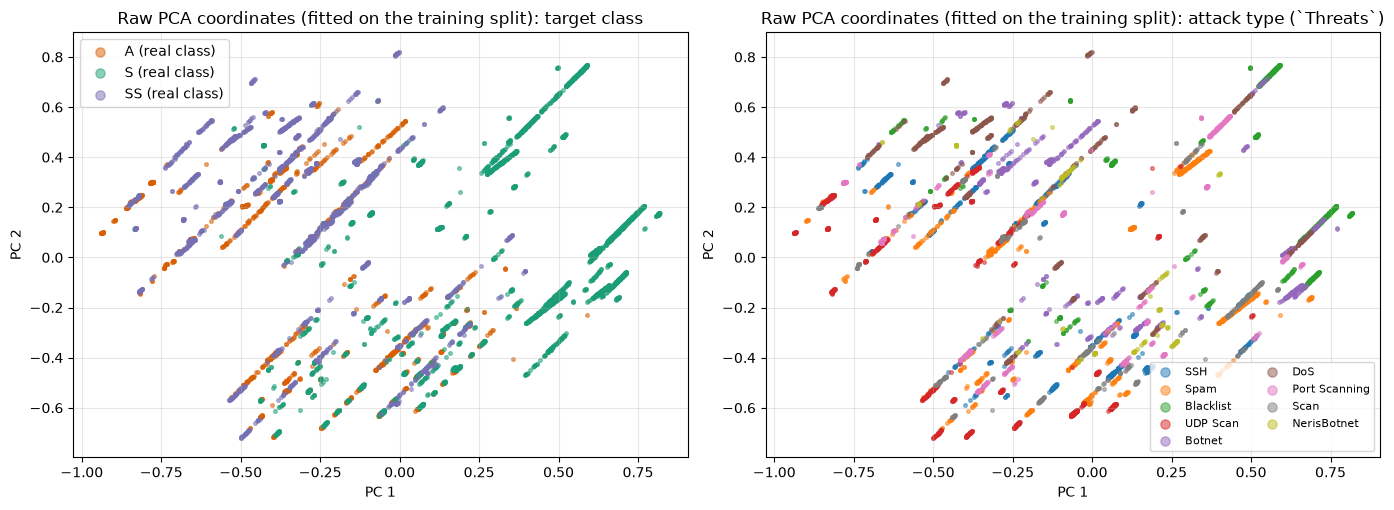

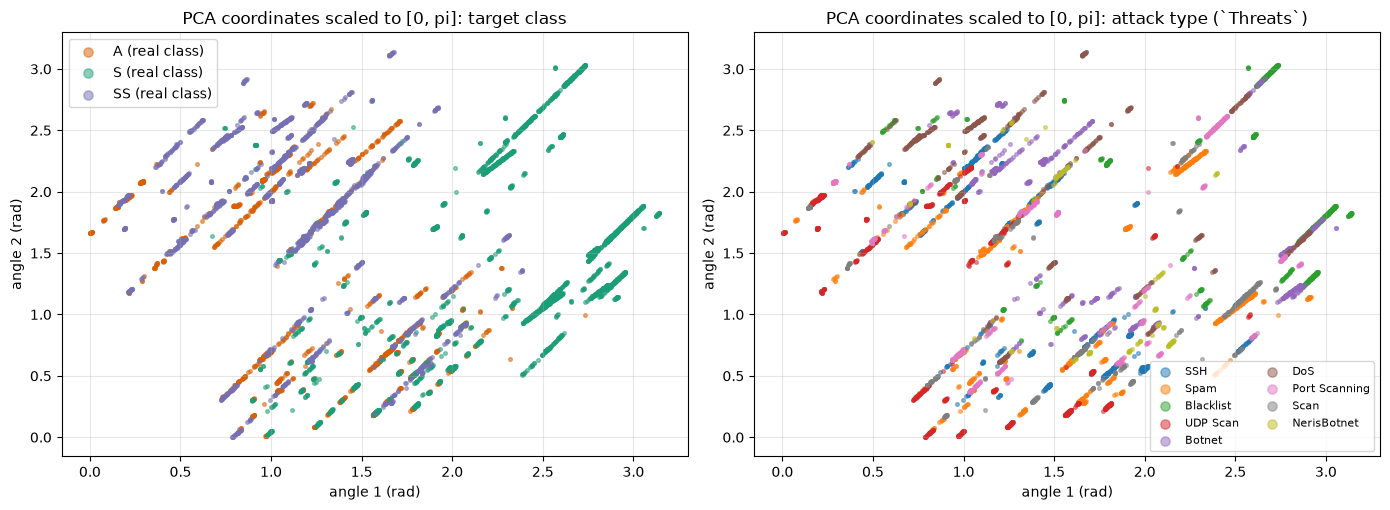

In [8]:
# PCA and the angle plots of the six selected features. Everything is fitted on the training split.
rng_plot = np.random.default_rng(SEED)
idx_plot = rng_plot.choice(len(Xtr), size=min(6000, len(Xtr)), replace=False)
THREAT_ORDER = list(df["Threats"].value_counts().index)
cmap_t = plt.get_cmap("tab10")
col_cls = {0: "#d95f02", 1: "#1b9e77", 2: "#7570b3"}

def scatter_two(P, title, xlabel, ylabel, jitter=0.0):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
    Pj = P + (np.random.default_rng(1).normal(0, jitter, P.shape) if jitter else 0)
    for c, name in enumerate(CLASSES):
        m = ytr[idx_plot] == c
        ax[0].scatter(Pj[m, 0], Pj[m, 1], s=7, alpha=0.5, c=col_cls[c], label=f"{name} (real class)")
    ax[0].legend(markerscale=2.5); ax[0].set_title(title + ": target class")
    thr = train_df["Threats"].values[idx_plot]
    for k, t in enumerate(THREAT_ORDER):
        m = thr == t
        ax[1].scatter(Pj[m, 0], Pj[m, 1], s=7, alpha=0.5, color=cmap_t(k % 10), label=t)
    ax[1].legend(markerscale=2.5, fontsize=8, ncol=2); ax[1].set_title(title + ": attack type (`Threats`)")
    for a in ax: a.set_xlabel(xlabel); a.set_ylabel(ylabel)
    plt.tight_layout(); plt.show()

cols6 = feat_idx[6]
pca = PCA(n_components=2, random_state=SEED).fit(Xtr[:, cols6])
P_tr = pca.transform(Xtr[:, cols6])
print("PCA on the 6 selected features, explained variance:", pca.explained_variance_ratio_.round(3))
scatter_two(P_tr[idx_plot], "Raw PCA coordinates (fitted on the training split)", "PC 1", "PC 2")

pmm = MinMaxScaler((0, np.pi)).fit(P_tr)
scatter_two(np.clip(pmm.transform(P_tr[idx_plot]), 0, np.pi), "PCA coordinates scaled to [0, pi]", "angle 1 (rad)", "angle 2 (rad)")

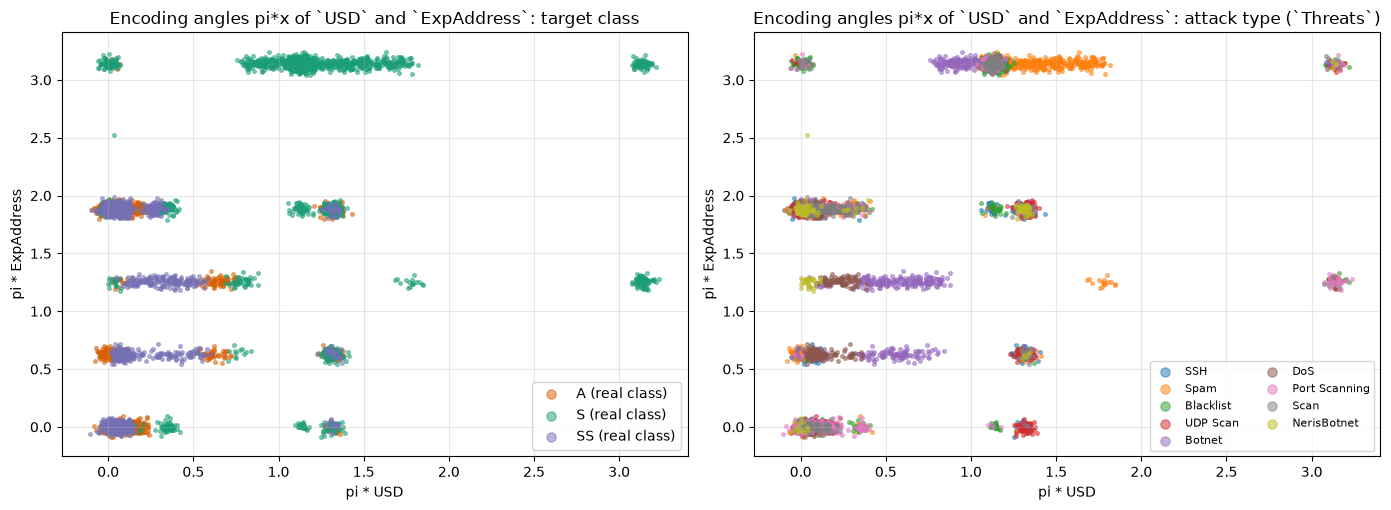

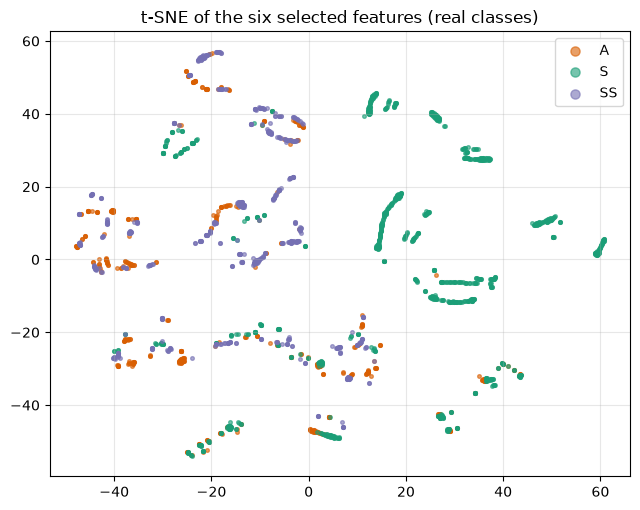

t-SNE took 123 s. Class S forms mostly its own groups; A and SS are interleaved inside the same groups, so no 2-D view separates all three classes.


In [9]:
# The angles the circuit really receives: pi * x_j for the two best chi2 features (one flow = one point; the features are
# partly discrete, so a tiny jitter of 0.03 rad is added for display only).
top2 = feat_idx[3][:2]
A2 = np.pi * Xtr[idx_plot][:, top2]
scatter_two(A2, f"Encoding angles pi*x of `{RANK[0]}` and `{RANK[1]}`", f"pi * {RANK[0]}", f"pi * {RANK[1]}", jitter=0.03)

# t-SNE of the six selected features (paper Fig. 3), on a 2000-flow sample of the training split.
idx_ts = idx_plot[:2000]
t0 = time.time()
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Xtr[idx_ts][:, cols6])
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for c, name in enumerate(CLASSES):
    m = ytr[idx_ts] == c
    ax.scatter(emb[m, 0], emb[m, 1], s=7, alpha=0.6, c=col_cls[c], label=name)
ax.legend(markerscale=2.5); ax.set_title("t-SNE of the six selected features (real classes)")
plt.tight_layout(); plt.show()
print(f"t-SNE took {time.time()-t0:.0f} s. Class S forms mostly its own groups; A and SS are interleaved inside the same groups, so no 2-D view separates all three classes.")

## 3. The classical models of the paper (Tables 8-11, Fig. 6a-c)

All classical models use the **top-6 chi-squared features** (the paper's input), trained on the 80 % training split and tested on the
20 % test split. The paper's SMOTE experiments are run twice:

* **leak-free**: borderline-SMOTE / SMOTEENN is fitted on the training split only and the test split is left untouched;
* **resample-then-split** (what the paper's support counts suggest: Tables 9-10 evaluate 29,794 rows although the test split holds
  22,381): the whole dataset is oversampled first and then split, so synthetic copies of test flows sit in the training data.

In `FAST_MODE` the classical models are trained on a stratified subsample of the training split (`N_CLASSICAL_TRAIN`).

In [10]:
def stratified_idx(y, n, rng):
    """Stratified sample of n row indices that keeps the class proportions of y."""
    parts = []
    for c in range(len(CLASSES)):
        ic = np.where(y == c)[0]
        k = int(round(n * len(ic) / len(y)))
        parts.append(rng.choice(ic, size=min(k, len(ic)), replace=False))
    idx = np.concatenate(parts); rng.shuffle(idx)
    return idx

def class_report(yt, yp):
    p, r, f, s = precision_recall_fscore_support(yt, yp, labels=[0, 1, 2], zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    fw = f1_score(yt, yp, average="weighted", zero_division=0)
    return dict(acc=accuracy_score(yt, yp), prec=pm, rec=rm, f1=fm, f1_weighted=fw,
                per_class={CLASSES[i]: (p[i], r[i], f[i], int(s[i])) for i in range(3)})

CLS = {}        # name -> dict(report, confusion, times)
def evaluate(name, model, Xa, ya, Xb, yb, resampler=None):
    t0 = time.time()
    if resampler is not None:
        Xa, ya = resampler.fit_resample(Xa, ya)
    model.fit(Xa, ya); t1 = time.time()
    yp = model.predict(Xb); t2 = time.time()
    rep = class_report(yb, yp)
    try:
        rep["auc"] = roc_auc_score(yb, model.predict_proba(Xb), multi_class="ovr")
    except Exception:
        rep["auc"] = np.nan
    CLS[name] = dict(report=rep, cm=confusion_matrix(yb, yp, labels=[0, 1, 2]), t_fit=t1 - t0, t_pred=t2 - t1)
    return rep

from sklearn.pipeline import make_pipeline
sub = stratified_idx(ytr, N_CLASSICAL_TRAIN, np.random.default_rng(SEED)) if N_CLASSICAL_TRAIN else np.arange(len(Xtr))
c6, c13 = feat_idx[6], list(range(len(FEATURES)))
Xa6, Xb6, ya_, yb_ = Xtr[sub][:, c6], Xte[:, c6], ytr[sub], yte
print(f"classical models: {len(sub):,} training flows, {len(yb_):,} test flows, features: {[FEATURES[i] for i in c6]}")

def sgd_svm(): return make_pipeline(StandardScaler(), CalibratedClassifierCV(SGDClassifier(loss="hinge", random_state=SEED), cv=3))
evaluate("LinearSVC (Table 8)", LinearSVC(max_iter=100, random_state=SEED), Xa6, ya_, Xb6, yb_)
evaluate("SVM + borderline-SMOTE, leak-free (Table 9)", sgd_svm(), Xa6, ya_, Xb6, yb_,
         BorderlineSMOTE(k_neighbors=6, random_state=SEED))
evaluate("SVM + SMOTEENN, leak-free (Table 10)", sgd_svm(), Xa6, ya_, Xb6, yb_, SMOTEENN(random_state=SEED))
evaluate("Naive Bayes (Table 11)", GaussianNB(), Xa6, ya_, Xb6, yb_)
evaluate("Random Forest (Table 11)", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2), Xa6, ya_, Xb6, yb_)
evaluate("XGBoost (Table 11)", XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.2, random_state=SEED, n_jobs=2, verbosity=0), Xa6, ya_, Xb6, yb_)
evaluate("Voting ensemble NB+RF+XGB (Table 11)", VotingClassifier([
    ("nb", GaussianNB()), ("rf", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)),
    ("xgb", XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.2, random_state=SEED, n_jobs=2, verbosity=0))],
    voting="soft"), Xa6, ya_, Xb6, yb_)
# same models on all 13 features (the paper's input is the top-6; this shows what the extra columns add)
Xa13, Xb13 = Xtr[sub][:, c13], Xte[:, c13]
evaluate("Random Forest, all 13 features", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2), Xa13, ya_, Xb13, yb_)
evaluate("Naive Bayes, all 13 features", GaussianNB(), Xa13, ya_, Xb13, yb_)
evaluate("SVM + borderline-SMOTE, all 13 features", sgd_svm(), Xa13, ya_, Xb13, yb_, BorderlineSMOTE(k_neighbors=6, random_state=SEED))
evaluate("XGBoost, all 13 features", XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.2, random_state=SEED, n_jobs=2, verbosity=0), Xa13, ya_, Xb13, yb_)

classical models: 15,000 training flows, 22,389 test flows, features: ['USD', 'ExpAddress', 'Port', 'Clusters', 'Netflow_Bytes', 'Threats']


{'acc': 0.9951315378087454,
 'prec': 0.9943348816445199,
 'rec': 0.995210605282678,
 'f1': 0.9947692980773414,
 'f1_weighted': 0.9951351532670158,
 'per_class': {'A': (np.float64(0.9875283446712018),
   np.float64(0.9933472723816765),
   np.float64(0.9904292618212831),
   5261),
  'S': (np.float64(0.9965072280974095),
   np.float64(0.9939036191213471),
   np.float64(0.9952037207499637),
   10334),
  'SS': (np.float64(0.9989690721649485),
   np.float64(0.9983809243450104),
   np.float64(0.9986749116607774),
   6794)},
 'auc': 0.9999152760384318}

In [11]:
# The paper's order of operations for SMOTE: oversample the WHOLE dataset first, then split 80:20 (leakage).
Xall = np.vstack([Xtr, Xte])[:, c6]; yall = np.concatenate([ytr, yte])
if N_CLASSICAL_TRAIN:      # FAST_MODE: keep the demo small
    keep = stratified_idx(yall, min(len(yall), N_CLASSICAL_TRAIN * 5 // 4), np.random.default_rng(SEED))
    Xall, yall = Xall[keep], yall[keep]
def leaky(name, resampler):
    Xr, yr = resampler.fit_resample(Xall, yall)
    Xa, Xb, ya, yb = train_test_split(Xr, yr, test_size=TEST_SIZE, stratify=yr, random_state=SEED)
    rep = evaluate(name, sgd_svm(), Xa, ya, Xb, yb)
    print(f"{name}: resampled data {len(yr):,} rows, 'test' split {len(yb):,} rows (paper: 29,794), accuracy {rep['acc']:.4f}")
leaky("SVM + borderline-SMOTE, resample-then-split", BorderlineSMOTE(k_neighbors=6, random_state=SEED))
leaky("SVM + SMOTEENN, resample-then-split", SMOTEENN(random_state=SEED))

CLS_DF = pd.DataFrame([{"model": k, "accuracy": v["report"]["acc"], "macro precision": v["report"]["prec"],
                        "macro recall": v["report"]["rec"], "macro F1": v["report"]["f1"], "AUC (ovr)": v["report"]["auc"],
                        "fit s": v["t_fit"], "predict s": v["t_pred"]} for k, v in CLS.items()]).set_index("model")
display(CLS_DF.round(4))

SVM + borderline-SMOTE, resample-then-split: resampled data 25,962 rows, 'test' split 5,193 rows (paper: 29,794), accuracy 0.7142


SVM + SMOTEENN, resample-then-split: resampled data 24,572 rows, 'test' split 4,915 rows (paper: 29,794), accuracy 0.8098


,accuracy,macro precision,macro recall,macro F1,AUC (ovr),fit s,predict s
model,,,,,,,
LinearSVC (Table 8),0.8133,0.7877,0.7875,0.7861,NaN,1.4821,0.0200
"SVM + borderline-SMOTE, leak-free (Table 9)",0.8063,0.7797,0.7852,0.7814,0.9004,19.6104,1.0216
"SVM + SMOTEENN, leak-free (Table 10)",0.8062,0.7806,0.7838,0.7811,0.9022,15.0537,0.1613
Naive Bayes (Table 11),0.7856,0.7496,0.7481,0.7468,0.8900,0.1032,0.1831
Random Forest (Table 11),0.9715,0.9693,0.9684,0.9688,0.9968,4.0982,0.5239
XGBoost (Table 11),0.9753,0.9739,0.9722,0.9730,0.9988,228.5804,0.4855
Voting ensemble NB+RF+XGB (Table 11),0.9731,0.9721,0.9693,0.9706,0.9953,203.0044,3.3600
"Random Forest, all 13 features",0.9918,0.9907,0.9913,0.9910,0.9997,3.6634,0.9998
"Naive Bayes, all 13 features",0.7922,0.7607,0.7602,0.7575,0.9107,0.0767,0.1222


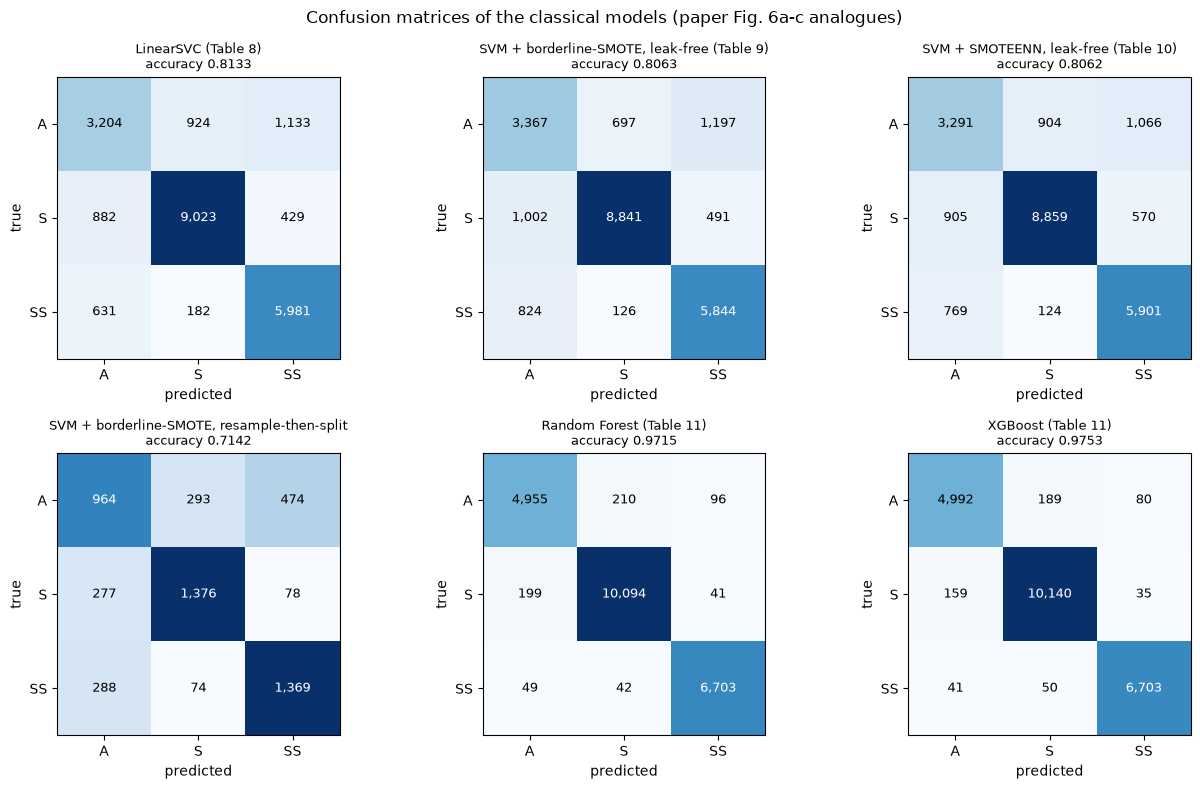

In [12]:
def plot_cm(ax, cm, title):
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9); ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)

names = ["LinearSVC (Table 8)", "SVM + borderline-SMOTE, leak-free (Table 9)", "SVM + SMOTEENN, leak-free (Table 10)",
         "SVM + borderline-SMOTE, resample-then-split", "Random Forest (Table 11)", "XGBoost (Table 11)"]
fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, nm in zip(axs.ravel(), names):
    plot_cm(ax, CLS[nm]["cm"], f"{nm}\naccuracy {CLS[nm]['report']['acc']:.4f}")
plt.suptitle("Confusion matrices of the classical models (paper Fig. 6a-c analogues)"); plt.tight_layout(); plt.show()

## 4. The quantum kernel: the circuit, an exact simulator, and the checks

**The circuit (paper Eqs. 14-16).** For `n` qubits and a flow `x` with features `x_1..x_n` in [0, 1], one repetition applies, on every qubit `j`,
`H`, then `RZ(gamma_j * sin(omega_j * x_j + phi_j))`, then `RY(pi * s * x_j)` (`s` is an angle scale tuned on validation data, `s = 1` in the paper),
followed by a `CZ` gate for every edge `(i, j)` of the mutual-information graph. `REPS = 2` repetitions are stacked. The kernel is
`K(x, x') = |<psi(x)|psi(x')>|^2`.

**Why a Hadamard layer.** Eq. 14 of the paper applies `RZ` directly to `|0>`; `RZ` only multiplies `|0>` by a phase, so in a single layer `gamma, omega, phi` would
never influence the kernel (with stacked repetitions they would only act from the second one on). The cell below shows this numerically. The `H` layer (as in the `ZZFeatureMap` the paper names in Section 4.2) fixes that.

**Two implementations of the same circuit.**
1. **Qiskit** (`QuantumCircuit`, `ParameterVector`) used with `FidelityStatevectorKernel` and `QSVC`: this is the circuit that is drawn in the next sections;
2. a small **NumPy statevector simulator** that applies the same gate list to a whole batch of flows at once. It is only there for speed (training and
   thousands of kernel entries); Section 8 checks it against Qiskit with `np.allclose`.

In [13]:
H1 = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)

def _apply1(psi, G, q, n):
    """Apply a 2x2 gate (fixed (2,2) or one per sample (B,2,2)) on qubit q. Qubit 0 is the last tensor axis (Qiskit order)."""
    ax = n - q
    psi = np.moveaxis(psi, ax, -1)
    psi = psi @ G.T if G.ndim == 2 else np.einsum("bij,b...j->b...i", G, psi)
    return np.moveaxis(psi, -1, ax)

def _idx(n, fixed):
    idx = [slice(None)] * (n + 1)
    for q, bit in fixed.items(): idx[n - q] = bit
    return tuple(idx)

def _rz_mat(th):
    G = np.zeros((len(th), 2, 2), complex); G[:, 0, 0] = np.exp(-0.5j * th); G[:, 1, 1] = np.exp(0.5j * th); return G
def _ry_mat(th):
    c, s = np.cos(th / 2), np.sin(th / 2)
    return np.stack([np.stack([c, -s], -1), np.stack([s, c], -1)], -2).astype(complex)
def _p_mat(th):
    G = np.zeros((len(th), 2, 2), complex); G[:, 0, 0] = 1; G[:, 1, 1] = np.exp(1j * th); return G

def _zero(B, n):
    psi = np.zeros((B,) + (2,) * n, complex); psi[(slice(None),) + (0,) * n] = 1; return psi

def pqese_states(X, n, edges, g, w, p, s=1.0, reps=REPS, hadamard=True):
    """Statevectors (B, 2^n) of the parameterised encoding with CZ on `edges` (the paper's PQESE circuit)."""
    X = np.asarray(X, float); psi = _zero(len(X), n)
    for _ in range(reps):
        if hadamard:
            for q in range(n): psi = _apply1(psi, H1, q, n)
        for q in range(n): psi = _apply1(psi, _rz_mat(g[q] * np.sin(w[q] * X[:, q] + p[q])), q, n)
        for q in range(n): psi = _apply1(psi, _ry_mat(np.pi * s * X[:, q]), q, n)
        for (i, j) in edges:
            psi[_idx(n, {i: 1, j: 1})] *= -1
    return psi.reshape(len(X), -1)

def zz_states(Xang, n, reps=REPS):
    """Statevectors of Qiskit's zz_feature_map(n, reps, entanglement='linear') for data angles Xang (B, n)."""
    Xang = np.asarray(Xang, float); psi = _zero(len(Xang), n)
    for _ in range(reps):
        for q in range(n): psi = _apply1(psi, H1, q, n)
        for q in range(n): psi = _apply1(psi, _p_mat(2 * Xang[:, q]), q, n)
        for q in range(n - 1):
            ph = np.exp(2j * (np.pi - Xang[:, q]) * (np.pi - Xang[:, q + 1]))
            for a, b in ((0, 1), (1, 0)):
                ix = _idx(n, {q: a, q + 1: b})
                sub_ = psi[ix]; psi[ix] = sub_ * ph.reshape((-1,) + (1,) * (sub_.ndim - 1))
    return psi.reshape(len(Xang), -1)

def kernel_from_states(SA, SB=None):
    SB = SA if SB is None else SB
    return np.abs(SA.conj() @ SB.T) ** 2

def build_qc(n, edges, g, w, p, s=1.0, reps=REPS, hadamard=True):
    """The Qiskit circuit that is executed: data enter through the ParameterVector x; gamma/omega/phi are numbers."""
    x = ParameterVector("x", n); qc = QuantumCircuit(n, name="PQESE")
    for r in range(reps):
        if hadamard:
            for q in range(n): qc.h(q)
        for q in range(n): qc.rz(float(g[q]) * (float(w[q]) * x[q] + float(p[q])).sin(), q)
        for q in range(n): qc.ry(float(np.pi * s) * x[q], q)
        for (i, j) in edges: qc.cz(i, j)
        if r < reps - 1: qc.barrier()
    return qc

def mi_edges(Xcols, tau=TAU, bins=MI_BINS):
    """Pairs (i, j) whose histogram mutual information (nats) exceeds tau; Xcols is the [0,1]-scaled training block."""
    n = Xcols.shape[1]; Bn = np.minimum((Xcols * bins).astype(int), bins - 1)
    M = np.zeros((n, n))
    for i, j in itertools.combinations(range(n), 2):
        M[i, j] = M[j, i] = mutual_info_score(Bn[:, i], Bn[:, j])
    return [(i, j) for i, j in itertools.combinations(range(n), 2) if M[i, j] > tau], M

In [14]:
# Check 1: without a Hadamard layer gamma, omega, phi cannot change the kernel (RZ on |0> is a global phase); with it they do.
rng_t = np.random.default_rng(0); Xt = rng_t.random((12, 4)); e4 = [(0, 1), (1, 2), (2, 3)]
g0, w0, p0 = np.full(4, np.pi), np.full(4, np.pi / 2), np.zeros(4)
for reps_ in (1, REPS):
    for had in (False, True):
        K_a = kernel_from_states(pqese_states(Xt, 4, e4, g0, w0, p0, reps=reps_, hadamard=had))
        K_b = kernel_from_states(pqese_states(Xt, 4, e4, 2 * g0, 3 * w0, p0 + 0.7, reps=reps_, hadamard=had))
        print(f"repetitions={reps_}, hadamard={had!s:5}: max |K(params A) - K(params B)| = {np.abs(K_a - K_b).max():.2e}")
print("With one repetition and no Hadamard layer the encoding parameters have exactly zero effect; with two repetitions they only act from the second one on.")

repetitions=1, hadamard=False: max |K(params A) - K(params B)| = 1.55e-15
repetitions=1, hadamard=True : max |K(params A) - K(params B)| = 9.23e-01
repetitions=2, hadamard=False: max |K(params A) - K(params B)| = 6.81e-01
repetitions=2, hadamard=True : max |K(params A) - K(params B)| = 4.34e-01
With one repetition and no Hadamard layer the encoding parameters have exactly zero effect; with two repetitions they only act from the second one on.


### Mutual-information graph (paper Eq. 15, tau = 0.05)

The edges depend only on the training features, not on labels. The matrix below is the histogram mutual information (nats) between
the selected features; an edge exists where it exceeds `TAU`.

3 qubits, qubit -> feature: {0: 'USD', 1: 'ExpAddress', 2: 'Port'}; CZ edges: [(0, 1), (0, 2), (1, 2)]


4 qubits, qubit -> feature: {0: 'USD', 1: 'ExpAddress', 2: 'Port', 3: 'Clusters'}; CZ edges: [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3)]


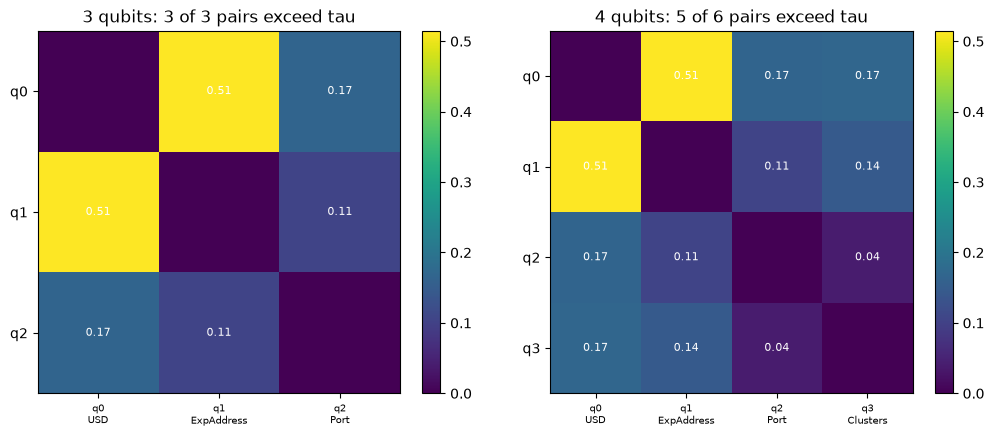

In [15]:
EDGES, MI_MATS = {}, {}
fig, axs = plt.subplots(1, len(QUBIT_COUNTS), figsize=(5.2 * len(QUBIT_COUNTS), 4.4))
axs = np.atleast_1d(axs)
for ax, n in zip(axs, QUBIT_COUNTS):
    e, M = mi_edges(Xtr[:, feat_idx[n]])
    EDGES[n], MI_MATS[n] = e, M
    im = ax.imshow(M, cmap="viridis"); ax.grid(False)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels([f"q{k}\n{RANK[k]}" for k in range(n)], fontsize=7); ax.set_yticklabels([f"q{k}" for k in range(n)])
    for i in range(n):
        for j in range(n):
            if i != j: ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax.set_title(f"{n} qubits: {len(e)} of {n*(n-1)//2} pairs exceed tau")
    plt.colorbar(im, ax=ax, fraction=0.046)
    print(f"{n} qubits, qubit -> feature: {dict(enumerate(RANK[:n]))}; CZ edges: {e}")
plt.tight_layout(); plt.show()

### Training the encoding parameters (kernel-target alignment)

The paper trains `gamma_j, omega_j, phi_j` with Adam but never names the loss. A kernel needs a kernel-level objective, so we maximise the **centred
kernel-target alignment** of the training kernel with the ideal label kernel `T_ij = 1[y_i = y_j]` (a standard objective for quantum kernels): Adam steps with
central finite-difference gradients (`3n` parameters, `KTA_STEPS` steps, `N_KTA` training flows). Initial values `gamma = pi, omega = pi/2, phi = 0` plus a small seeded perturbation (CHOICE).

In [16]:
def center(K):
    m = len(K); Hc = np.eye(m) - 1.0 / m; return Hc @ K @ Hc

def kta_score(K, Tc):
    Kc = center(K); return float((Kc * Tc).sum() / (np.linalg.norm(Kc) * np.linalg.norm(Tc) + 1e-12))

def init_params(n, rng):
    return np.concatenate([np.full(n, np.pi), np.full(n, np.pi / 2), np.zeros(n)]) + rng.normal(0, 0.1, 3 * n)

def train_params(Xk, yk, n, edges, s, p0, steps, lr):
    """Adam ascent on the centred alignment; returns the final parameters and the alignment history."""
    Tc = center((yk[:, None] == yk[None, :]).astype(float))
    f = lambda p: kta_score(kernel_from_states(pqese_states(Xk, n, edges, p[:n], p[n:2*n], p[2*n:], s)), Tc)
    p, m, v, hist = p0.copy(), np.zeros_like(p0), np.zeros_like(p0), [f(p0)]
    for t in range(1, steps + 1):
        grad = np.zeros_like(p)
        for i in range(len(p)):
            e = np.zeros_like(p); e[i] = 1e-3; grad[i] = (f(p + e) - f(p - e)) / 2e-3
        m = 0.9 * m + 0.1 * grad; v = 0.999 * v + 0.001 * grad ** 2
        p = p + lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        hist.append(f(p))
    return p, hist

## 5. Training and evaluating the QSVM (Table 12, Fig. 6d) and its ablations

For each qubit count `n` and each seed the notebook draws a stratified sample of `N_TRAIN_Q` training and `N_TEST_Q` test flows from the 80 : 20 split and runs

| kind | encoding | entanglement | trained parameters |
|---|---|---|---|
| `PQESE` | the paper's parameterised encoding | CZ on mutual-information edges (sparse) | yes (alignment) |
| `PQESE-untrained` | same | same | no (initial values) |
| `PQESE-full` | same | CZ on all pairs | yes |
| `PQESE-noent` | same | none | yes |
| `ZZ` | Qiskit `zz_feature_map(reps=2, entanglement="linear")`, the standard kernel | linear chain | none |
| `PQESE-nosel` | `PQESE` on the first `n` columns instead of the chi-squared top `n` (ablation of the feature selection) | MI graph of those columns | yes |

The angle scale `s` and the SVM's `C` are chosen on a validation part of the training sample, never on test data. The classical SVMs (linear, polynomial, RBF) get exactly the same flows, features and `C` grid.

In [17]:
SAMPLES = {}
for sd in SEEDS:
    r = np.random.default_rng(sd)
    SAMPLES[sd] = (stratified_idx(ytr, N_TRAIN_Q, r), stratified_idx(yte, N_TEST_Q, r))

def states_for(kind, X, n, spec, s):
    if kind == "ZZ": return zz_states(np.pi * s * X, n)
    return pqese_states(X, n, spec["edges"], spec["g"], spec["w"], spec["p"], s)

def run_quantum(kind, n, seed):
    t_all = time.time()
    itr, ite = SAMPLES[seed]
    cols = list(range(n)) if kind == "PQESE-nosel" else feat_idx[n]       # natural-order columns for the ablation
    A, Bm, ya, yb = Xtr[itr][:, cols], Xte[ite][:, cols], ytr[itr], yte[ite]
    rng = np.random.default_rng(seed)
    a_in, a_val = train_test_split(np.arange(len(A)), test_size=VAL_FRACTION, stratify=ya, random_state=seed)
    if kind in ("PQESE", "PQESE-untrained", "PQESE-nosel"):
        edges = EDGES[n] if kind != "PQESE-nosel" else mi_edges(Xtr[:, cols])[0]
    elif kind == "PQESE-full": edges = list(itertools.combinations(range(n), 2))
    elif kind == "PQESE-noent": edges = []
    else: edges = []
    p0 = np.round(init_params(n, rng), 3); spec = dict(edges=edges, g=p0[:n], w=p0[n:2*n], p=p0[2*n:]); hist = []
    if kind not in ("ZZ", "PQESE-untrained"):
        kk = a_in[:N_KTA]
        pf, hist = train_params(A[kk], ya[kk], n, edges, 1.0, p0, KTA_STEPS, KTA_LR)
        pf = np.round(pf, 3)                       # 3 decimals: the executed circuit and its drawing use exactly these numbers
        spec = dict(edges=edges, g=pf[:n], w=pf[n:2*n], p=pf[2*n:])
    # choose angle scale s and C on the validation part of the training sample
    best = (-1, None, None)
    for s in SCALE_GRID:
        S_A = states_for(kind, A, n, spec, s); K_A = kernel_from_states(S_A)
        for C in C_GRID:
            clf = SVC(kernel="precomputed", C=C).fit(K_A[np.ix_(a_in, a_in)], ya[a_in])
            acc = accuracy_score(ya[a_val], clf.predict(K_A[np.ix_(a_val, a_in)]))
            if acc > best[0]: best = (acc, s, C)
    val_acc, s, C = best
    S_A = states_for(kind, A, n, spec, s); S_B = states_for(kind, Bm, n, spec, s)
    K_A, K_B = kernel_from_states(S_A), kernel_from_states(S_B, S_A)
    t_fit0 = time.time(); clf = SVC(kernel="precomputed", C=C).fit(K_A, ya); t_fit = time.time() - t_fit0
    yp = clf.predict(K_B)
    rep = class_report(yb, yp)
    return dict(kind=kind, n=n, seed=seed, report=rep, cm=confusion_matrix(yb, yp, labels=[0, 1, 2]), spec=spec, scale=s, C=C,
                val_acc=val_acc, kta_hist=hist, y_true=yb, y_pred=yp, ite=ite, itr=itr, cols=cols,
                n_sv=int(clf.n_support_.sum()), seconds=time.time() - t_all)

def run_classical_same(n, seed):
    """SVMs (linear / polynomial / RBF) + NB + RF + XGBoost on exactly the flows and features of the quantum run."""
    itr, ite = SAMPLES[seed]; cols = feat_idx[n]
    A, Bm, ya, yb = Xtr[itr][:, cols], Xte[ite][:, cols], ytr[itr], yte[ite]
    a_in, a_val = train_test_split(np.arange(len(A)), test_size=VAL_FRACTION, stratify=ya, random_state=seed)
    out = {}
    for name, kw in (("SVM linear", dict(kernel="linear")), ("SVM polynomial", dict(kernel="poly")), ("SVM RBF", dict(kernel="rbf"))):
        bestC = max(C_GRID[::-1], key=lambda C: accuracy_score(ya[a_val], SVC(C=C, **kw).fit(A[a_in], ya[a_in]).predict(A[a_val])))
        t0 = time.time(); clf = SVC(C=bestC, **kw).fit(A, ya); yp = clf.predict(Bm)
        out[name] = dict(report=class_report(yb, yp), cm=confusion_matrix(yb, yp, labels=[0, 1, 2]), C=bestC, seconds=time.time() - t0)
    for name, clf in (("Naive Bayes", GaussianNB()), ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=2)),
                      ("XGBoost", XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.2, random_state=seed, n_jobs=2, verbosity=0))):
        t0 = time.time(); yp = clf.fit(A, ya).predict(Bm)
        out[name] = dict(report=class_report(yb, yp), cm=confusion_matrix(yb, yp, labels=[0, 1, 2]), seconds=time.time() - t0)
    return out

In [18]:
KINDS = ["PQESE", "PQESE-untrained", "PQESE-full", "PQESE-noent", "ZZ"]
QRES, CRES = {}, {}
t_start = time.time()
for sd in SEEDS:
    for n in QUBIT_COUNTS:
        CRES[(n, sd)] = run_classical_same(n, sd)
        for kind in KINDS:
            r = run_quantum(kind, n, sd); QRES[(kind, n, sd)] = r
            print(f"seed {sd} | {n} qubits | {kind:16s} acc {r['report']['acc']:.4f}  macro-F1 {r['report']['f1']:.4f}  "
                  f"(edges {len(r['spec']['edges'])}, s={r['scale']}, C={r['C']}, {r['seconds']:.0f} s)")
    if ABLATION_QUBITS in QUBIT_COUNTS:
        r = run_quantum("PQESE-nosel", ABLATION_QUBITS, sd); QRES[("PQESE-nosel", ABLATION_QUBITS, sd)] = r
        print(f"seed {sd} | {ABLATION_QUBITS} qubits | PQESE-nosel      acc {r['report']['acc']:.4f}  macro-F1 {r['report']['f1']:.4f}")
print(f"total quantum sweep: {(time.time()-t_start)/60:.1f} min")

seed 42 | 3 qubits | PQESE            acc 0.7233  macro-F1 0.6544  (edges 3, s=1.0, C=1.0, 15 s)


seed 42 | 3 qubits | PQESE-untrained  acc 0.7100  macro-F1 0.6583  (edges 3, s=1.0, C=1.0, 1 s)


seed 42 | 3 qubits | PQESE-full       acc 0.7233  macro-F1 0.6544  (edges 3, s=1.0, C=1.0, 14 s)


seed 42 | 3 qubits | PQESE-noent      acc 0.7550  macro-F1 0.6774  (edges 0, s=1.0, C=10.0, 19 s)


seed 42 | 3 qubits | ZZ               acc 0.7433  macro-F1 0.6767  (edges 0, s=1.0, C=10.0, 1 s)


...

seed 42 | 4 qubits | PQESE-untrained  acc 0.8533  macro-F1 0.8305  (edges 5, s=1.0, C=10.0, 0 s)


seed 42 | 4 qubits | PQESE-full       acc 0.8550  macro-F1 0.8329  (edges 6, s=1.0, C=10.0, 34 s)


seed 42 | 4 qubits | PQESE-noent      acc 0.8617  macro-F1 0.8397  (edges 0, s=1.0, C=10.0, 44 s)


seed 42 | 4 qubits | ZZ               acc 0.8783  macro-F1 0.8649  (edges 0, s=1.0, C=10.0, 0 s)


seed 42 | 4 qubits | PQESE-nosel      acc 0.7750  macro-F1 0.7672
total quantum sweep: 7.5 min


In [19]:
def agg(kind, n, key="acc"):
    v = [QRES[(kind, n, sd)]["report"][key] for sd in SEEDS if (kind, n, sd) in QRES]
    return (np.mean(v), np.std(v)) if v else (np.nan, np.nan)
def agg_c(model, n, key="acc"):
    v = [CRES[(n, sd)][model]["report"][key] for sd in SEEDS]
    return np.mean(v), np.std(v)

rows = []
for n in QUBIT_COUNTS:
    for kind in KINDS + (["PQESE-nosel"] if n == ABLATION_QUBITS else []):
        a, sa = agg(kind, n); f, sf = agg(kind, n, "f1"); fw, sfw = agg(kind, n, "f1_weighted")
        rows.append(dict(qubits=n, model="QSVM " + kind, accuracy=f"{a:.4f} ± {sa:.4f}", macro_F1=f"{f:.4f} ± {sf:.4f}", weighted_F1=f"{fw:.4f} ± {sfw:.4f}"))
    for model in CRES[(n, SEEDS[0])]:
        a, sa = agg_c(model, n); f, sf = agg_c(model, n, "f1"); fw, sfw = agg_c(model, n, "f1_weighted")
        rows.append(dict(qubits=n, model=model + " (same flows)", accuracy=f"{a:.4f} ± {sa:.4f}", macro_F1=f"{f:.4f} ± {sf:.4f}", weighted_F1=f"{fw:.4f} ± {sfw:.4f}"))
SUMMARY = pd.DataFrame(rows)
print(f"mean ± std over seeds {SEEDS}; {N_TRAIN_Q} training / {N_TEST_Q} test flows per seed")
display(SUMMARY.set_index(["qubits", "model"]))

mean ± std over seeds [42]; 240 training / 600 test flows per seed


accuracy         macro_F1  \
qubits model                                                           
3      QSVM PQESE                   0.7233 ± 0.0000  0.6544 ± 0.0000   
       QSVM PQESE-untrained         0.7100 ± 0.0000  0.6583 ± 0.0000   
       QSVM PQESE-full              0.7233 ± 0.0000  0.6544 ± 0.0000   
       QSVM PQESE-noent             0.7550 ± 0.0000  0.6774 ± 0.0000   
       QSVM ZZ                      0.7433 ± 0.0000  0.6767 ± 0.0000   
       SVM linear (same flows)      0.7117 ± 0.0000  0.6671 ± 0.0000   
       SVM polynomial (same flows)  0.7200 ± 0.0000  0.6689 ± 0.0000   
       SVM RBF (same flows)         0.7267 ± 0.0000  0.6752 ± 0.0000   
       Naive Bayes (same flows)     0.6800 ± 0.0000  0.5881 ± 0.0000   
       Random Forest (same flows)   0.8550 ± 0.0000  0.8341 ± 0.0000   
       XGBoost (same flows)         0.8300 ± 0.0000  0.8088 ± 0.0000   
4      QSVM PQESE                   0.8567 ± 0.0000  0.8337 ± 0.0000   
       QSVM PQESE-untrained         0.8533 ± 0.0000  0.8305 ± 0.0000   
       QSVM PQESE-full              0.8550 ± 0.0000  0.8329 ± 0.0000   
       QSVM PQESE-noent             0.8617 ± 0.0000  0.8397 ± 0.0000   
       QSVM ZZ                      0.8783 ± 0.0000  0.8649 ± 0.0000   
       QSVM PQESE-nosel             0.7750 ± 0.0000  0.7672 ± 0.0000   
       SVM linear (same flows)      0.7850 ± 0.0000  0.7562 ± 0.0000   
       SVM polynomial (same flows)  0.7700 ± 0.0000  0.7415 ± 0.0000   
       SVM RBF (same flows)         0.7333 ± 0.0000  0.6809 ± 0.0000   
       Naive Bayes (same flows)     0.7567 ± 0.0000  0.7009 ± 0.0000   
       Random Forest (same flows)   0.8883 ± 0.0000  0.8761 ± 0.0000   
       XGBoost (same flows)         0.8667 ± 0.0000  0.8544 ± 0.0000   

                                        weighted_F1  
qubits model                                         
3      QSVM PQESE                   0.7098 ± 0.0000  
       QSVM PQESE-untrained         0.7076 ± 0.0000  
       QSVM PQESE-full              0.7098 ± 0.0000  
       QSVM PQESE-noent             0.7346 ± 0.0000  
       QSVM ZZ                      0.7293 ± 0.0000  
       SVM linear (same flows)      0.7148 ± 0.0000  
       SVM polynomial (same flows)  0.7171 ± 0.0000  
       SVM RBF (same flows)         0.7254 ± 0.0000  
       Naive Bayes (same flows)     0.6571 ± 0.0000  
       Random Forest (same flows)   0.8544 ± 0.0000  
       XGBoost (same flows)         0.8304 ± 0.0000  
4      QSVM PQESE                   0.8547 ± 0.0000  
       QSVM PQESE-untrained         0.8517 ± 0.0000  
       QSVM PQESE-full              0.8534 ± 0.0000  
       QSVM PQESE-noent             0.8594 ± 0.0000  
       QSVM ZZ                      0.8774 ± 0.0000  
       QSVM PQESE-nosel             0.7749 ± 0.0000  
       SVM linear (same flows)      0.7870 ± 0.0000  
       SVM polynomial (same flows)  0.7729 ± 0.0000  
       SVM RBF (same flows)         0.7310 ± 0.0000  
       Naive Bayes (same flows)     0.7464 ± 0.0000  
       Random Forest (same flows)   0.8887 ± 0.0000  
       XGBoost (same flows)         0.8669 ± 0.0000

## 6. Metrics: per-class table (Table 12), confusion matrices (Fig. 6d), per-attack recall (Table 13), alignment curves

Table 12 of the paper gives, for each class, a one-vs-rest accuracy / precision / recall / F1 of the SVM (linear, polynomial, RBF) and of the QSVM with 3 and 4 qubits.
Below: the same layout for seed 42.

In [20]:
sd0 = SEEDS[0]
rows = []
for n in QUBIT_COUNTS:
    for model in ("SVM linear", "SVM polynomial", "SVM RBF"):
        pc = CRES[(n, sd0)][model]["report"]["per_class"]
        for c in CLASSES: rows.append(dict(qubits=n, model=model, **{"class": c}, precision=pc[c][0], recall=pc[c][1], F1=pc[c][2], support=pc[c][3]))
    pc = QRES[("PQESE", n, sd0)]["report"]["per_class"]
    for c in CLASSES: rows.append(dict(qubits=n, model="QSVM PQESE", **{"class": c}, precision=pc[c][0], recall=pc[c][1], F1=pc[c][2], support=pc[c][3]))
T12 = pd.DataFrame(rows)
display(T12.pivot_table(index=["class", "model"], columns="qubits", values=["precision", "recall", "F1"]).round(4))

F1         precision          recall        
qubits                     3       4         3       4       3       4
class model                                                           
A     QSVM PQESE      0.3565  0.6963    0.4607  0.7287  0.2908  0.6667
      SVM RBF         0.4270  0.4335    0.4524  0.4672  0.4043  0.4043
      SVM linear      0.4214  0.5874    0.4245  0.5793  0.4184  0.5957
      SVM polynomial  0.4111  0.5614    0.4643  0.5556  0.3688  0.5674
S     QSVM PQESE      0.8759  0.9068    0.9137  0.9185  0.8412  0.8953
      SVM RBF         0.8848  0.8905    0.9119  0.9160  0.8592  0.8664
      SVM linear      0.8626  0.8780    0.9150  0.9141  0.8159  0.8448
      SVM polynomial  0.8622  0.8622    0.9481  0.9481  0.7906  0.7906
SS    QSVM PQESE      0.7306  0.8982    0.6250  0.8557  0.8791  0.9451
      SVM RBF         0.7139  0.7186    0.6620  0.6620  0.7747  0.7857
      SVM linear      0.7172  0.8031    0.6636  0.7688  0.7802  0.8407
      SVM polynomial  0.7335  0.8010    0.6265  0.7244  0.8846  0.8956

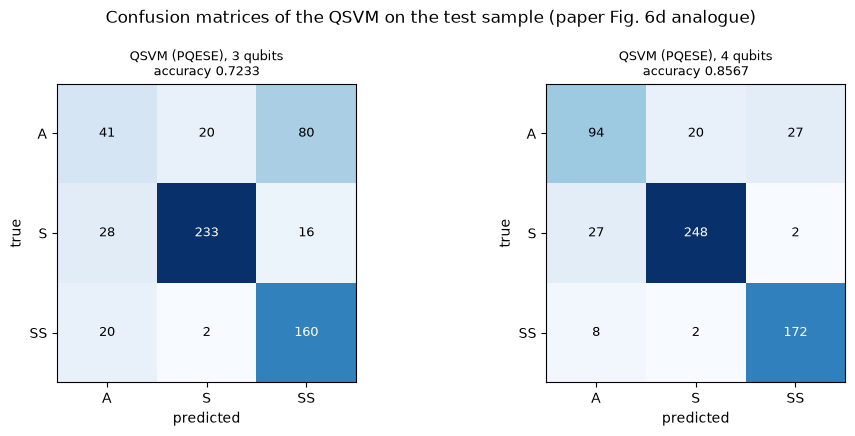

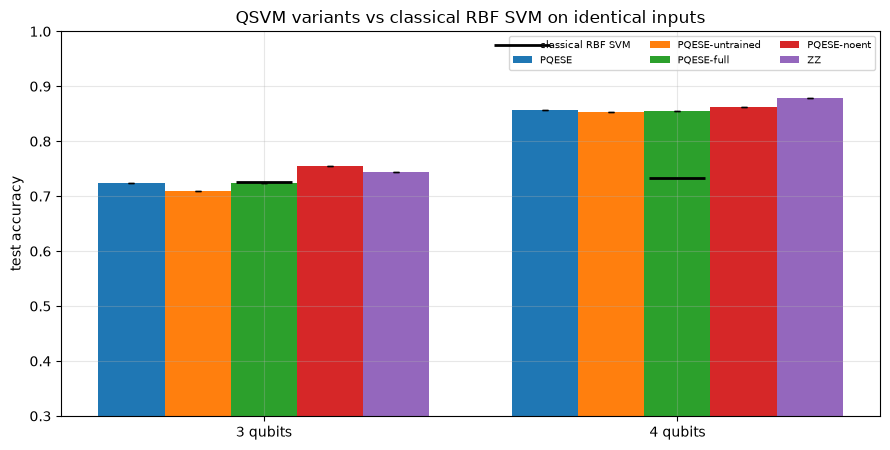

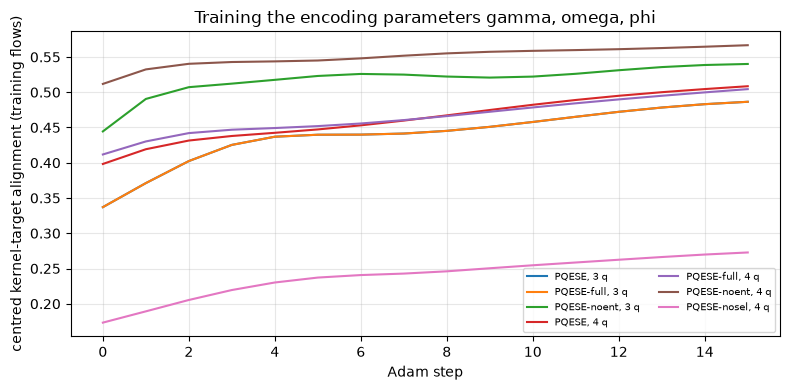

In [21]:
fig, axs = plt.subplots(1, len(QUBIT_COUNTS), figsize=(5 * len(QUBIT_COUNTS), 4.4))
for ax, n in zip(np.atleast_1d(axs), QUBIT_COUNTS):
    r = QRES[("PQESE", n, sd0)]
    plot_cm(ax, r["cm"], f"QSVM (PQESE), {n} qubits\naccuracy {r['report']['acc']:.4f}")
plt.suptitle("Confusion matrices of the QSVM on the test sample (paper Fig. 6d analogue)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.6))
kinds_plot = KINDS; w = 0.8 / len(kinds_plot); xs = np.arange(len(QUBIT_COUNTS))
for k, kind in enumerate(kinds_plot):
    m = [agg(kind, n)[0] for n in QUBIT_COUNTS]; s_ = [agg(kind, n)[1] for n in QUBIT_COUNTS]
    ax.bar(xs + k * w, m, w, yerr=s_, label=kind, capsize=2)
m = [agg_c("SVM RBF", n)[0] for n in QUBIT_COUNTS]
ax.plot(xs + 0.4 - w / 2, m, "k_", markersize=40, mew=2, label="classical RBF SVM")
ax.set_xticks(xs + 0.4 - w / 2); ax.set_xticklabels([f"{n} qubits" for n in QUBIT_COUNTS]); ax.set_ylabel("test accuracy")
ax.set_ylim(0.3, 1.0); ax.set_title("QSVM variants vs classical RBF SVM on identical inputs"); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for (kind, n, sd), r in QRES.items():
    if sd == sd0 and r["kta_hist"]:
        ax.plot(r["kta_hist"], label=f"{kind}, {n} q")
ax.set_xlabel("Adam step"); ax.set_ylabel("centred kernel-target alignment (training flows)")
ax.set_title("Training the encoding parameters gamma, omega, phi"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

In [22]:
# Paper Table 13 reports recall-like numbers "per attack type"; the definition is not given. We report the recall of the
# QSVM (PQESE) for every real attack type (`Threats`) and ransomware `Family` in the test sample: the share of those flows
# that received their correct target class.
nq = QUBIT_COUNTS[-1] if 4 not in QUBIT_COUNTS else 4
r = QRES[("PQESE", nq, sd0)]
tt = test_df["Threats"].values[r["ite"]]; ff = test_df["Family"].values[r["ite"]]
ok = (r["y_true"] == r["y_pred"])
t13 = pd.DataFrame({"Threats": tt, "correct": ok}).groupby("Threats")["correct"].agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "flows"})
f13 = pd.DataFrame({"Family": ff, "correct": ok}).groupby("Family")["correct"].agg(["mean", "size"]).rename(columns={"mean": "recall", "size": "flows"})
print(f"QSVM (PQESE, {nq} qubits, seed {sd0}): recall per real attack type and per ransomware family")
display(pd.concat([t13.round(4), f13.round(4)], keys=["Threats", "Family"]))

QSVM (PQESE, 4 qubits, seed 42): recall per real attack type and per ransomware family


recall  flows
Threats Blacklist         0.9882     85
        Botnet            0.8971     68
        DoS               0.9531     64
        NerisBotnet       0.6842     19
        Port Scanning     0.9259     54
        SSH               0.7419     93
        Scan              0.8250     40
        Spam              0.8298     94
        UDP Scan          0.7831     83
Family  APT               0.9143     35
        CryptXXX          0.9000     40
        CryptoLocker2015  1.0000      1
        Cryptohitman      0.8462     13
        DMALocker         0.9200     50
        EDA2              1.0000     22
        Flyper            0.9000     50
        Globe             0.7667     30
        JigSaw            0.8276     58
        Locky             0.8673     98
        NoobCrypt         1.0000      9
        Razy              0.9032     31
        SamSam            0.7568     74
        TowerWeb          0.5882     17
        WannaCry          0.8611     72

## Quantum Circuit Architecture

The circuits below are the Qiskit `QuantumCircuit` objects that `FidelityStatevectorKernel` executes for the seed-42 PQESE model of each qubit count, with the
trained `gamma, omega, phi` written into the gates (`x[j]` are the data parameters). Each qubit carries `H`, `RZ(gamma sin(omega x + phi))`, `RY(pi s x)`;
the vertical `CZ` lines are the mutual-information edges; the dashed barrier separates the two repetitions. The kernel circuit of a pair of flows is
`U(x')^dagger U(x)`; the drawing shows `U(x)`. Assumptions where the paper is silent: Hadamard layer, `REPS = 2`, angle scale `s`, the edge list (from the MI estimate),
and the ordering `H, RZ, RY, CZ` inside a repetition.

PQESE, 3 qubits | features ['USD', 'ExpAddress', 'Port'] | CZ edges [(0, 1), (0, 2), (1, 2)] | angle scale s=1.0
   qubits 3 | depth 12 | data parameters 3 | trainable parameters 9 (gamma, omega, phi per qubit) | gates {'h': 6, 'rz': 6, 'ry': 6, 'cz': 6, 'barrier': 1}


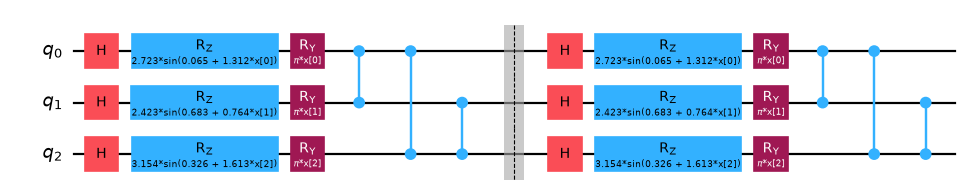

PQESE, 4 qubits | features ['USD', 'ExpAddress', 'Port', 'Clusters'] | CZ edges [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3)] | angle scale s=1.0
   qubits 4 | depth 14 | data parameters 4 | trainable parameters 12 (gamma, omega, phi per qubit) | gates {'cz': 10, 'h': 8, 'rz': 8, 'ry': 8, 'barrier': 1}


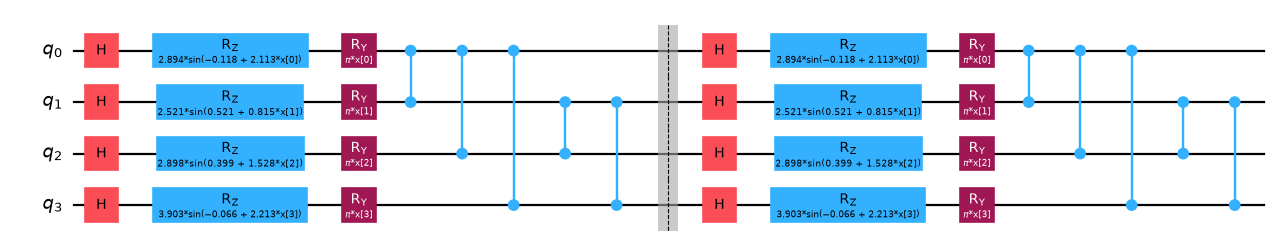

In [23]:
CIRCUITS = {}
for n in QUBIT_COUNTS:
    r = QRES[("PQESE", n, sd0)]; sp = r["spec"]
    qc = build_qc(n, sp["edges"], sp["g"], sp["w"], sp["p"], r["scale"])
    CIRCUITS[n] = qc
    print(f"PQESE, {n} qubits | features {RANK[:n]} | CZ edges {sp['edges']} | angle scale s={r['scale']}")
    print(f"   qubits {qc.num_qubits} | depth {qc.depth()} | data parameters {qc.num_parameters} | trainable parameters {3*n} (gamma, omega, phi per qubit) "
          f"| gates {dict(qc.count_ops())}")
    fig = qc.draw("mpl", fold=60, scale=0.8)
    display(fig); plt.close(fig)

ZZFeatureMap baseline, 4 qubits | qubits 4 | depth 19 | data parameters 4 | trainable parameters 0 | gates {'u': 22, 'cx': 12}


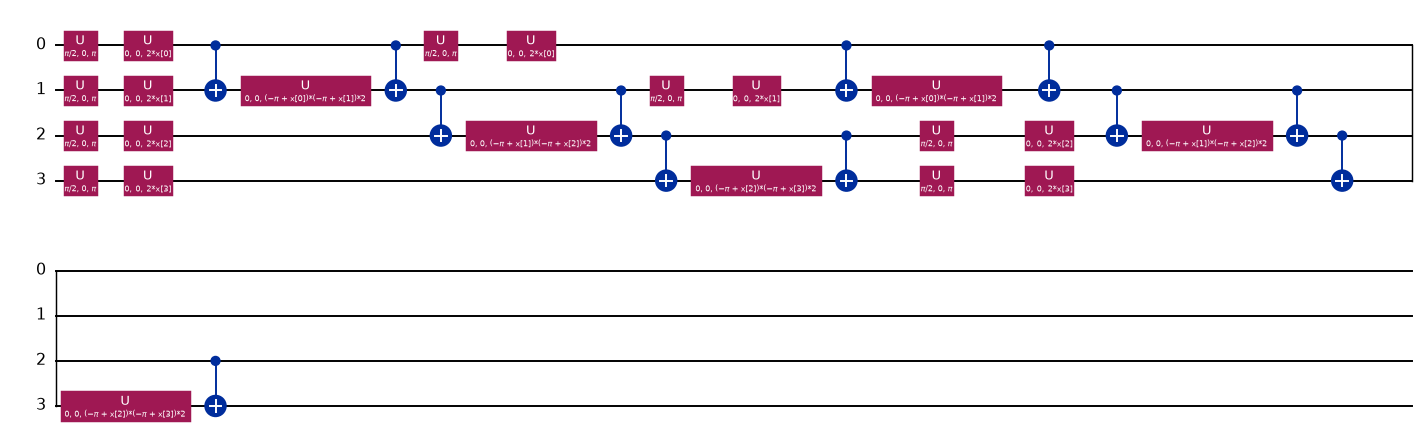

3 qubits: drawn Qiskit circuit == NumPy simulator kernel (max abs diff 3.6e-15)
4 qubits: drawn Qiskit circuit == NumPy simulator kernel (max abs diff 4.0e-15)


ZZFeatureMap 4 qubits: Qiskit kernel == NumPy simulator kernel


In [24]:
# The standard kernel used as a baseline: Qiskit's own ZZFeatureMap (one drawing: 4 qubits, or the smallest qubit count).
nz = 4 if 4 in QUBIT_COUNTS else QUBIT_COUNTS[0]
zzc = zz_feature_map(nz, reps=REPS, entanglement="linear")
zzd = zzc.decompose()
print(f"ZZFeatureMap baseline, {nz} qubits | qubits {zzd.num_qubits} | depth {zzd.depth()} | data parameters {zzc.num_parameters} | trainable parameters 0 | gates {dict(zzd.count_ops())}")
fig = zzd.draw("mpl", fold=30, scale=0.7); display(fig); plt.close(fig)

# Equivalence between the drawn circuits and the simulator that produced the numbers above (exact statevector kernels).
for n in QUBIT_COUNTS:
    r = QRES[("PQESE", n, sd0)]; sp = r["spec"]
    Xs = Xte[r["ite"][:10]][:, r["cols"]]
    K_qiskit = FidelityStatevectorKernel(feature_map=CIRCUITS[n]).evaluate(Xs)
    K_numpy = kernel_from_states(pqese_states(Xs, n, sp["edges"], sp["g"], sp["w"], sp["p"], r["scale"]))
    assert np.allclose(K_qiskit, K_numpy, atol=1e-9), f"circuit and simulator disagree for n={n}"
    print(f"{n} qubits: drawn Qiskit circuit == NumPy simulator kernel (max abs diff {np.abs(K_qiskit-K_numpy).max():.1e})")
Xs = np.random.default_rng(3).random((8, nz))
K_zq = FidelityStatevectorKernel(feature_map=zz_feature_map(nz, reps=REPS, entanglement="linear")).evaluate(np.pi * Xs)
assert np.allclose(K_zq, kernel_from_states(zz_states(np.pi * Xs, nz)), atol=1e-9)
print(f"ZZFeatureMap {nz} qubits: Qiskit kernel == NumPy simulator kernel")

## 7. Cross-check with the Qiskit stack: `FidelityStatevectorKernel` + `QSVC`

The big sweeps above use the NumPy simulator. Here the **same trained circuits** go through Qiskit Machine Learning's own pipeline on a small subsample of the seed-42 flows
(the first `N_CHECK_TRAIN` training and `N_CHECK_TEST` test flows): the kernel matrix from `FidelityStatevectorKernel`, a `QSVC` fit and predict, and the hand-computed
kernel `|<phi(a)|phi(b)>|^2` from `Statevector` objects fed to `SVC(kernel="precomputed")`. All three must agree (`np.allclose`, identical predictions).

In [25]:
rows = []
for n in QUBIT_COUNTS:
    r = QRES[("PQESE", n, sd0)]; sp = r["spec"]; cols = r["cols"]
    A_s, ya_s = Xtr[r["itr"][:N_CHECK_TRAIN]][:, cols], ytr[r["itr"][:N_CHECK_TRAIN]]
    B_s, yb_s = Xte[r["ite"][:N_CHECK_TEST]][:, cols], yte[r["ite"][:N_CHECK_TEST]]
    qc = CIRCUITS[n]
    qk = FidelityStatevectorKernel(feature_map=qc)
    t0 = time.time(); qsvc = QSVC(quantum_kernel=qk, C=r["C"]).fit(A_s, ya_s); pred_qsvc = qsvc.predict(B_s); t_q = time.time() - t0
    # hand-computed kernel straight from Qiskit Statevector objects of the bound circuit
    def sv(row): return Statevector(qc.assign_parameters(list(row))).data
    SA = np.array([sv(a) for a in A_s]); SB = np.array([sv(b) for b in B_s])
    K_hand_AA, K_hand_BA = np.abs(SA.conj() @ SA.T) ** 2, np.abs(SB.conj() @ SA.T) ** 2
    K_np_AA = kernel_from_states(pqese_states(A_s, n, sp["edges"], sp["g"], sp["w"], sp["p"], r["scale"]))
    K_np_BA = kernel_from_states(pqese_states(B_s, n, sp["edges"], sp["g"], sp["w"], sp["p"], r["scale"]),
                                 pqese_states(A_s, n, sp["edges"], sp["g"], sp["w"], sp["p"], r["scale"]))
    K_qk_BA = qk.evaluate(B_s, A_s)
    assert np.allclose(K_hand_BA, K_qk_BA, atol=1e-9) and np.allclose(K_hand_BA, K_np_BA, atol=1e-9) and np.allclose(K_hand_AA, K_np_AA, atol=1e-9)
    pred_pre = SVC(kernel="precomputed", C=r["C"]).fit(K_hand_AA, ya_s).predict(K_hand_BA)
    rows.append(dict(qubits=n, kernels_allclose=True, QSVC_equals_precomputed_SVC=bool((pred_qsvc == pred_pre).all()),
                     QSVC_test_accuracy=accuracy_score(yb_s, pred_qsvc), n_train=len(A_s), n_test=len(B_s), qsvc_seconds=round(t_q, 1)))
display(pd.DataFrame(rows).set_index("qubits"))

,kernels_allclose,QSVC_equals_precomputed_SVC,QSVC_test_accuracy,n_train,n_test,qsvc_seconds
qubits,,,,,,
3,True,True,0.80,40,25,1.1
4,True,True,0.88,40,25,1.3


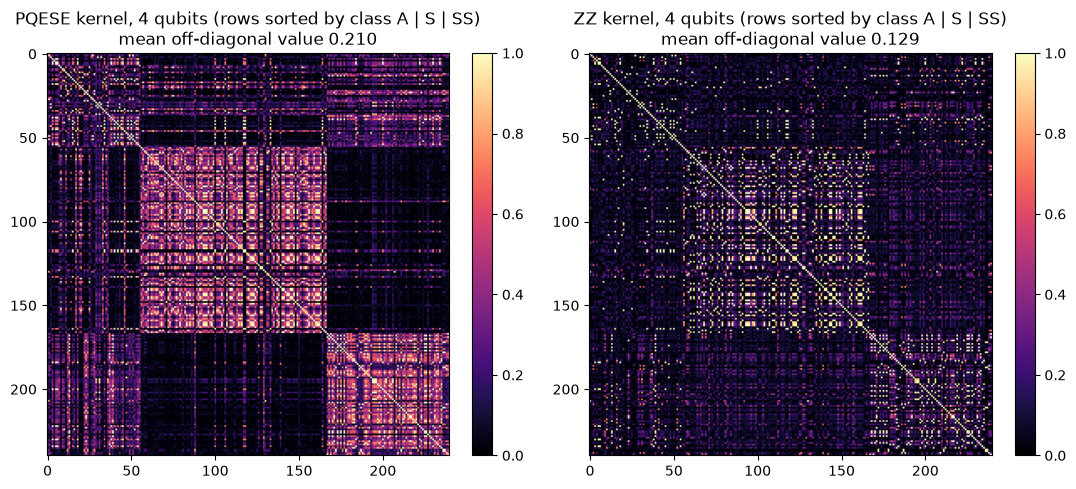

In [26]:
# What the learned kernel looks like: training-sample kernel matrices sorted by class (4 qubits, seed 42): the PQESE kernel vs the standard ZZ kernel.
nk = 4 if 4 in QUBIT_COUNTS else QUBIT_COUNTS[0]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, kind in zip(axs, ["PQESE", "ZZ"]):
    r = QRES[(kind, nk, sd0)]; ii = r["itr"][:300]; order = np.argsort(ytr[ii], kind="stable")
    Xk = Xtr[ii][:, r["cols"]][order]
    K = kernel_from_states(states_for(kind, Xk, nk, r["spec"], r["scale"]))
    im = ax.imshow(K, cmap="magma", vmin=0, vmax=1); ax.grid(False)
    ax.set_title(f"{kind} kernel, {nk} qubits (rows sorted by class A | S | SS)\nmean off-diagonal value {K[~np.eye(len(K), dtype=bool)].mean():.3f}")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 8. Paper versus this notebook

Each row is one number (or one qualitative claim) of the paper. The verdict is **reproduced** when our value is within 0.02 of the paper's
(two accuracy points, 0.02 in F1), **exceeded** when it is more than 0.02 above, **not reached** when it is more than 0.02 below, and
**cannot be checked** when the paper does not define the quantity or it needs data we do not have. The paper's QSVM "precision / recall / F1" columns
equal a *weighted* average (recall equals accuracy), so we compare with the weighted F1. QSVM numbers are means over the seeds in the configuration.

In [27]:
def verdict(paper, ours, tol=0.02):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

def qa(kind, n, key="acc"): return agg(kind, n, key)[0] if n in QUBIT_COUNTS else np.nan
n3, n4 = 3, 4
rows = []
def add(claim, paper, ours, note="", kind="num"):
    if kind == "num": v = verdict(paper, ours)
    else: v = kind
    rows.append(dict(claim=claim, paper=paper, notebook=ours, gap=(ours - paper) if kind == "num" and ours == ours else np.nan, verdict=v, note=note))

add("Linear SVM accuracy, top-6 features (Table 8)", 0.64, CLS["LinearSVC (Table 8)"]["report"]["acc"])
add("Linear SVM macro F1 (Table 8: 0.65, 0.65, 0.59)", 0.63, CLS["LinearSVC (Table 8)"]["report"]["f1"])
add("SVM + borderline-SMOTE accuracy (Table 9), leak-free", 0.998, CLS["SVM + borderline-SMOTE, leak-free (Table 9)"]["report"]["acc"], "SMOTE fitted on training split only")
add("SVM + borderline-SMOTE accuracy (Table 9), resample-then-split", 0.998, CLS["SVM + borderline-SMOTE, resample-then-split"]["report"]["acc"], "the paper's order of operations")
add("SVM + SMOTEENN accuracy (Table 10), leak-free", 0.981, CLS["SVM + SMOTEENN, leak-free (Table 10)"]["report"]["acc"])
add("SVM + SMOTEENN accuracy (Table 10), resample-then-split", 0.981, CLS["SVM + SMOTEENN, resample-then-split"]["report"]["acc"])
add("Naive Bayes accuracy (Table 11)", 0.99, CLS["Naive Bayes (Table 11)"]["report"]["acc"])
add("Random Forest accuracy (Table 11)", 1.00, CLS["Random Forest (Table 11)"]["report"]["acc"])
add("Voting ensemble accuracy (Table 11)", 1.00, CLS["Voting ensemble NB+RF+XGB (Table 11)"]["report"]["acc"])
add("XGBoost accuracy (Table 11)", 1.00, CLS["XGBoost (Table 11)"]["report"]["acc"])
add("Classical RBF SVM on the quantum inputs, 4 qubits (Table 12: 0.63)", 0.63, agg_c("SVM RBF", 4)[0] if 4 in QUBIT_COUNTS else np.nan)
add("QSVM accuracy, 3 qubits (Tables 12, 16)", 0.9794, qa("PQESE", 3))
add("QSVM weighted F1, 3 qubits (Table 16)", 0.9796, qa("PQESE", 3, "f1_weighted"))
add("QSVM accuracy, 4 qubits (Tables 12, 16)", 0.9911, qa("PQESE", 4))
add("QSVM weighted F1, 4 qubits (Table 16)", 0.9825, qa("PQESE", 4, "f1_weighted"))
add("QSVM accuracy quoted in the abstract (99.89 %)", 0.9989, max([qa("PQESE", n) for n in QUBIT_COUNTS]))

best_q = max([qa("PQESE", n) for n in QUBIT_COUNTS]); nq_ = 4 if 4 in QUBIT_COUNTS else QUBIT_COUNTS[-1]
rbf4 = agg_c("SVM RBF", nq_)[0]; q_at = qa("PQESE", nq_)
add("Claim: the QSVM clearly beats classical SVMs on the same inputs", np.nan, round(q_at - rbf4, 4),
    f"gap QSVM minus RBF SVM at {nq_} qubits (accuracy); claim holds if > 0.05", "reproduced" if q_at - rbf4 > 0.05 else "not reached")
if 3 in QUBIT_COUNTS and 4 in QUBIT_COUNTS:
    add("Claim: 4 qubits are better than 3 qubits", np.nan, round(qa("PQESE", 4) - qa("PQESE", 3), 4), "accuracy difference 4q - 3q",
        "reproduced" if qa("PQESE", 4) > qa("PQESE", 3) else "not reached")
nz_ = 4 if 4 in QUBIT_COUNTS else QUBIT_COUNTS[-1]
add("Claim: parameterised encoding + MI-sparse entanglement beats the standard ZZ kernel", np.nan, round(qa("PQESE", nz_) - qa("ZZ", nz_), 4),
    f"accuracy difference PQESE - ZZ at {nz_} qubits", "reproduced" if qa("PQESE", nz_) > qa("ZZ", nz_) + 0.01 else "not reached")
add("Claim: the trainable parameters help (untrained vs trained)", np.nan, round(qa("PQESE", nz_) - qa("PQESE-untrained", nz_), 4),
    f"accuracy difference at {nz_} qubits", "reproduced" if qa("PQESE", nz_) > qa("PQESE-untrained", nz_) + 0.01 else "not reached")
if ABLATION_QUBITS in QUBIT_COUNTS:
    drop = qa("PQESE", ABLATION_QUBITS, "f1_weighted") - qa("PQESE-nosel", ABLATION_QUBITS, "f1_weighted")
    add("Ablation (Table 16, 4 qubits): removing the feature selection lowers F1 from 0.9825 to 0.9328", 0.9825 - 0.9328, round(drop, 4),
        "F1 drop when the chi-squared selection is replaced by the first columns (the paper removes 't-SNE', which is not a selection method)",
        "reproduced" if abs(drop - 0.0497) <= 0.02 else ("exceeded" if drop > 0.0497 else "not reached"))
add("Claim (conclusions): the QSVM outperforms the ensemble / XGBoost models", np.nan, round(best_q - CLS["XGBoost (Table 11)"]["report"]["acc"], 4),
    "accuracy difference QSVM - XGBoost; claim holds if > 0 (Table 11 of the paper itself has XGBoost at 1.00)",
    "reproduced" if best_q > CLS["XGBoost (Table 11)"]["report"]["acc"] else "not reached")
add("Table 13: per-attack-type QSVM metrics (0.94-0.999)", np.nan, np.nan, "the definition of 'accuracy per attack, predicted label' is not given; our per-attack recall is in Section 6", "cannot be checked")
add("Table 17: Wilcoxon p = 0.031 for the 't-SNE' ablation", np.nan, np.nan, "t-SNE is not a feature-selection method; no comparable experiment", "cannot be checked")
add("Figs. 11, 13: comparison with prior studies, LIME explanations", np.nan, np.nan, "other papers' results / LIME not re-run", "cannot be checked")

PVN = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90, "display.width", 250)
display(PVN.round(4))
print(PVN["verdict"].value_counts().to_string())

,claim,paper,notebook,gap,verdict,note
0,"Linear SVM accuracy, top-6 features (Table 8)",0.6400,0.8133,0.1733,exceeded,
1,"Linear SVM macro F1 (Table 8: 0.65, 0.65, 0.59)",0.6300,0.7861,0.1561,exceeded,
2,"SVM + borderline-SMOTE accuracy (Table 9), leak-free",0.9980,0.8063,-0.1917,not reached,SMOTE fitted on training split only
3,"SVM + borderline-SMOTE accuracy (Table 9), resample-then-split",0.9980,0.7142,-0.2838,not reached,the paper's order of operations
4,"SVM + SMOTEENN accuracy (Table 10), leak-free",0.9810,0.8062,-0.1748,not reached,
5,"SVM + SMOTEENN accuracy (Table 10), resample-then-split",0.9810,0.8098,-0.1712,not reached,
6,Naive Bayes accuracy (Table 11),0.9900,0.7856,-0.2044,not reached,
7,Random Forest accuracy (Table 11),1.0000,0.9715,-0.0285,not reached,
8,Voting ensemble accuracy (Table 11),1.0000,0.9731,-0.0269,not reached,
9,XGBoost accuracy (Table 11),1.0000,0.9753,-0.0247,not reached,


verdict
not reached          16
exceeded              4
cannot be checked     3
reproduced            2


## Reading the paper critically

**What this run shows (FAST_MODE: 240 training and 600 test flows for the quantum kernels, seed 42; a single run, so the standard error of an accuracy is about 1.4 points).**
The paper's headline numbers are **not reached**: 3-qubit QSVM accuracy 0.72 (paper 0.979) and 4-qubit 0.86 (paper 0.991). In the verdict table 2 claims are reproduced (both
qualitative: the QSVM is better than the classical SVMs on the same inputs, and 4 qubits beat 3 qubits), 4 are exceeded (our linear and RBF SVMs are *better* than the paper's 0.57-0.64), 16 are not reached and 3 cannot be checked.
These numbers come from small quantum samples and a 15,000-flow classical training subsample. The full configuration (3 seeds, 3 / 4 / 6 qubits, 3,000 / 5,000 flows, all 89.5k flows for the classical
models) is written into the configuration cell but could not be completed here (see "Run time" below), so the gap to the paper is partly a sample-size effect that this notebook does not close.

**The classical part of the paper is not reproducible with the stated inputs.**
* A linear SVM on the six chi-squared features reaches 0.81, not 0.64. Borderline-SMOTE or SMOTEENN do not lift an SGD-trained linear SVM anywhere near 0.998 / 0.981 (about 0.81, and about 0.80 with all 13 features); the paper's "resample first, split afterwards" order does not produce those numbers either (the resample-then-split rows use a 25k-flow subsample in FAST_MODE).
* Tables 9 and 10 have 29,794 test rows although the test split has 22,381: the SMOTE models were scored on resampled data, so those two tables are not comparable with Tables 8 and 11.
* Random Forest and XGBoost reach 0.97 on the six features and 0.99+ on all 13 features, close to the paper's "perfect" scores but not equal to them. Naive Bayes reaches 0.79, not 0.99.

**The quantum claims are not supported by the evidence the paper gives.**
* *The entanglement is not sparse.* With `tau = 0.05` nats the mutual-information graph has 3 of 3 edges at 3 qubits and 5 of 6 at 4 qubits: it is (almost) the full graph. The "data-driven sparse topology" collapses into all-to-all entanglement for these features, and the paper never reports an edge count.
* *The components do not help here.* At 4 qubits the kernel without any entanglement (0.862) is as good as the MI graph (0.857) and full entanglement (0.855); the untrained encoding (0.853) is as good as the trained one; the plain Qiskit `ZZFeatureMap` (0.878) is better. All of these differences are within about one standard error.
* *A classical model on the same flows is better.* Random Forest on exactly the same 240 training flows and 4 features scores 0.888 and XGBoost 0.867, versus 0.857 for the QSVM. The paper's conclusion that the QSVM "outperformed ensemble-based classifiers" contradicts its own Table 11 (XGBoost 1.00).
* *The ablation is mis-specified.* Tables 16-17 remove "t-SNE feature selection", but t-SNE is a visualisation, not a selector. The ablation that makes sense (chi-squared selection versus the first columns) shows a large effect here (accuracy 0.857 versus 0.775), which supports the *classical* chi-squared step rather than the quantum circuit.
* *The circuit as written has a flaw.* Eq. 14 applies `RZ` to `|0>`, which is a global phase; in one layer the trainable `gamma, omega, phi` would be inert (Section 4 verifies it). We added a Hadamard layer.

**Internal inconsistencies worth knowing.** Table 6 lists PennyLane `default.qubit`, Section 4.2 uses Qiskit with 1024 shots on a statevector backend; Table 6 lists neural-network hyper-parameters (hidden layers, batch size, epochs, early stopping) that an SVM does not have; `k = 6`
features but "3 and 4 qubits"; the abstract gives 99.89 % accuracy but 98.95 % F1, while Table 12 gives an F1 of 0.9989 for 4 qubits; the QSVM confusion matrix of Fig. 6d sums to 29,726 flows; Table 13 lists a "Predicted" class for attack types (for example "Blacklist, A"), which is not a classification result; the code is available only on request.

**The dataset is probably easier than a real network.** UGRansome records look generated: in the first rows `USD` rises by a constant step of 4, and the flows lie on parallel lines in the PCA plot, so neighbouring records are likely to fall on both sides of a random 80 : 20 split, which favours tree models. A split that holds out whole ransomware families (a real zero-day protocol; exercise 2) would be much harder and is the test the title promises but the paper never runs. Class A is described as "benign and zero-day anomalies" (Table 4), so detecting it is not the same as detecting zero-days.

**Quantum advantage.** Six qubits mean 64-dimensional states simulated exactly on a CPU, and the kernel is computed classically. Nothing here tests noise, hardware or scaling, and the paper itself calls its result a proof of concept.

**Run time.** `FAST_MODE = True` is meant to finish in about 10 minutes on an idle laptop; on the shared machine where this notebook was executed it took 27 minutes (the classical models and t-SNE dominate). A first attempt at the full configuration was stopped after the classical block had taken 40 minutes and the quantum sweep still had not finished after about an hour on a heavily loaded CPU, so the outputs stored in this notebook are those of the FAST_MODE run. Set `FAST_MODE = False` in the configuration cell to run the full budgets.

## Exercises

1. **Sparse or not?** Set `TAU` to 0.2, 0.5 and 1.0 and re-run Sections 4 and 5. How many CZ edges remain at 4 qubits, and at which threshold does the circuit become really sparse? Does accuracy change by more than one standard error (use `SEEDS = [42, 43, 44]`)?
2. **A real zero-day protocol.** Replace the random 80 : 20 split by one that holds out four ransomware families (`Family`) entirely from training and test on them. Compare the QSVM, the ZZ kernel, the RBF SVM and Random Forest. Which model degrades least? Is the paper's claim about "unknown" threats still plausible?
3. **The paper's literal Eq. 14.** Call `pqese_states(..., reps=1, hadamard=False)` and show that the kernel does not depend on `gamma, omega, phi`. Which classifier remains (hint: which gates still depend on the data)?
4. **More data and more qubits.** Set `FAST_MODE = False` (or only enlarge `N_TRAIN_Q` and `N_TEST_Q` and add 6 to `QUBIT_COUNTS`). How do the accuracies of the QSVM and of Random Forest on the same flows scale with the number of training flows? Does the 3-qubit model ever approach 0.98?
5. **Different features.** The paper selects features with the chi-squared test on label-encoded text columns (an arbitrary ordering). Replace it by `mutual_info_classif`, or by PCA of all 13 scaled features, and compare the quantum kernel and the classical models. Does the ranking `USD, ExpAddress, Port, Clusters` survive?
6. **Leakage.** Apply `BorderlineSMOTE` to the full dataset before the split and use a nearest-neighbour search to count how many test flows have an almost identical synthetic training copy.